# 14 — Is MARCO expressed in tumour cells, SPP1-expressing macrophages or suppressive myeloid cells — and is it expressed widely at all?

**Why this notebook exists.** `Marco` (macrophage receptor with collagenous structure, a class-A scavenger
receptor) is on the PDF's SPP1-TAM readout list (`Trem2 / Gpnmb / Apoe / Fabp5 / Marco`) and in `01c`'s
`lipid_TREM2` check set. In `01c` §4a it was the **one** of 16 lipid / TREM2 genes that did *not* come up
significant (log2FC +1.92 but Wilcoxon padj 1.0; detected in 0.27% of Spp1-high vs 0.05% of Spp1-low
macrophages), and nobody has looked at it since. If MARCO is to be a handle on tumour cells, SPP1-TAMs or
suppressive myeloid cells, it has to be expressed in them. This notebook asks whether it is, with the
conventions of `mhcCytotoxExhaustion/01`, `/06` and `/08` (mouse = unit, ambient-RNA control, spatial
spill-over control, leave-one-mouse-out) and the SPP1-TAM definitions of `09` / `10`.

| Q | question | what answers it | § |
|---|---|---|---|
| **Q1** | Is MARCO **widely expressed** — in any cell type, mouse or condition? | % of cells with >= 1 UMI and pooled CPM for **every** population; comparator scavenger receptors; depth dependence; mouse coverage | 3 |
| **Q2** | Is it expressed in **tumour cells** — and are the few positive cells the tumour's own? | the `01` / `08` ambient model (and a calibration of it), the clean-cell test, and a **matched-control-gene null** | 4 |
| **Q3** | Is it expressed in **SPP1-expressing macrophages**? | seven definitions of that population; depth- and sample-matched rate ratio; mouse-level paired test; dose-response; co-expression | 5 |
| **Q4** | Is it expressed in **suppressive myeloid cells**? | every myeloid state (exhaustive); a pre-specified suppressive program that contains no Marco; adjusted against SPP1-TAM status | 6 |
| **Q5** | Does CAR or RT move it? | arm x site table; mouse-level exact relabelling | 7 |
| **Q6** | Does the **spatial** object — a different chemistry — agree? | per-label detection with the B-cell spill-over rule of `mhcCytotoxExhaustion/06` | 8 |

### Definitions fixed before looking
* **Detected** = at least 1 raw UMI in the cell (`layers['counts']`).
* **Expression level** = pooled pseudobulk **CPM** = sum of Marco UMI / sum of all UMI x 10^6 over the cells of a
  group — depth-normalised, and the unit the project's pseudobulk work uses.
* **Widely expressed** = detected in >= 5% (loose) or >= 10% (strict) of a population's cells **and** in most of
  that population's mice. These are the floors the project already applies before it tests any gene
  (`09` `DET_FLOOR = 0.10`, `12` `DETECT_FLOOR = 0.05`; `mhcCytotoxExhaustion/06` asks for >= 5% in the
  intended label), so the criterion is borrowed, not invented for this answer.

### The four ways a rare gene fools you (each gets a control)
1. **Depth.** A transcript at the edge of detection is detected in a cell roughly in proportion to how many UMIs
   that cell has, and SPP1-TAMs / `Apoe_high` macrophages are deeper libraries. A raw positive-cell count would
   manufacture an "enrichment". Every group comparison is therefore **matched on sample x within-sample depth
   bin** (effect = Mantel-Haenszel rate ratio; test = exact stratified permutation) and the pooled CPM is shown
   beside it, because the two estimators weigh multi-UMI cells differently.
2. **Background.** In a non-myeloid cell, a read or two is what leakage looks like. §4 asks whether tumour-cell
   Marco exceeds what **equally rare, myeloid-restricted genes** show in tumour cells — with the controls chosen
   from *non-tumour* cells only, because choosing them on a gene's total myeloid share would condition on the
   very quantity being tested (a first version of this control did exactly that and made Marco look extreme).
3. **One mouse.** §3 measures how much of the signal any single mouse carries; everything is leave-one-mouse-out,
   and the mouse is the unit for every test (exact sign-flip, cluster bootstrap over mice).
4. **Definition.** "SPP1-expressing macrophage" and "suppressive myeloid cell" are not single things. SPP1 is read
   **seven** ways (`09`'s four, the literal Spp1 transcript two ways, and the `Apoe_high_Mac` state); suppressive
   cells **three** ways (label, program score, gene-level). Marco is in neither the 50-gene SPP1-TAM signature nor
   the suppressive program, so no definition contains it.

### What this cannot measure
MARCO **protein**, surface display, ligand binding or function. Single-cell 3' RNA-seq samples a few thousand UMI
per cell, so a transcript present at ~1 CPM is mostly invisible per cell: "not detected" here is an **upper bound on
the transcript-positive fraction, not proof of absence**. The spatial object (probe-based, different chemistry) is
the closest thing to an orthogonal check the project has; flow cytometry or IHC would be the decisive one.

### Design rules (as `07` / `08`)
* **Mouse = unit**: 15 mice (3 NoTx + 12 treated; two tumours each, one missing). `NoTx` is a detection check,
  never a biological comparator (tumour-rich, shallow libraries).
* **No RT-alone arm.** Every RT contrast is "adding RT on top of Cy + CAR-T"; PSCA = PSCA CAR vs the non-specific
  TAG72 CAR.
* Helpers are **inline** (the HPC kernel cannot see local `.py` files); the notebook runs locally on
  `spatial_cpu_py311` and resolves its paths local-first, so the same file also runs on the cluster.

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, time, logging, re
from pathlib import Path
import numpy as np, pandas as pd, h5py, anndata as ad, scanpy as sc
import scipy.sparse as sp
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
logging.disable(logging.WARNING)
pd.set_option("display.width", 250, "display.max_columns", 60, "display.max_rows", 300)

# ---- paths: local copy first, then the two HPC spellings (same resolution as 12 / 13) ---------------
CANDIDATES = [Path("/Users/janzules/Roselab/Spatial/CAR_T"),
              Path("/coh_labs/yunroseli/Jona/CAR-T"),
              Path("/coh_labs/yunroseli/Jona/spatial/CAR-T")]
PROJ = next(p for p in CANDIDATES if p.exists())
_HPC = PROJ.as_posix().startswith("/coh_labs")
REF_DIR = (PROJ/"data/zarr/fullDataset/annotating_references") if _HPC else (PROJ/"data/sc-reference")
SC_REF  = REF_DIR/"annotation_v4.h5ad"                 # 93,548 x 22,949; .X log1p, layers['counts'] raw
MAC_REF = REF_DIR/"mac_annotation_v5.h5ad"             # only needed if LAB_PARQUET is missing (HPC)
LAB_PARQUET = PROJ/"results/spp1_analysis/mac_lvl3_lvl4_lvl5_labels.parquet"   # Alice's mac labels (12 / 00)
ZARR = (PROJ/"data/zarr/fullDataset/processing_Zarr/1_C2l_annotated_CC" if _HPC
        else PROJ/"data/zarrFiles/1_C2l_annotations_400")
GMT_DIR = PROJ/"data/references/pathways"
SIG_CSV = PROJ/"results/spp1_analysis/sc_spp1_tam_signature.csv"
DE_01C  = PROJ/"results/spp1_analysis/sc_de_spp1high_vs_low_macs_lvl2.csv"     # 01c §4a, for the cross-reference
MHC_PANEL = PROJ/"results/mhc_cytotox/cell_panel.parquet"                       # optional: reproduction check only
OUT = PROJ/"results/SpecificGenes/marco"; FIG = OUT/"figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
SP_CACHE = OUT/"14_spatial_marco_detection.npz"

# ---- design (as mhcCytotoxExhaustion/00) ----------------------------------------------------------
SC2ARM = {"NoTx": "NoTx", "CyPSCA": "CyPSCA", "CyTAG72": "CyT72", "RTCyPSCA": "RTCyPSCA", "RTCyTAG72": "RTCyT72"}
ARM_ORDER = ["NoTx", "CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"]
MAC  = ["M1_like_Mac", "M2_like_Mac", "Intermediate_Mac"]
MONO = ["Classical_Mono", "Nonclassical_Mono"]
NEU  = ["N1_like_Neu", "N2_like_Neu"]
MYELOID = MAC + MONO + NEU + ["cDC", "pDC"]

# ---- thresholds -------------------------------------------------------------------------------------
MIN_CELLS       = 20      # cells a population needs in a mouse to count that mouse as "eligible" (09 / 10 floor)
MIN_MOUSE_CELLS = 50      # cells a mouse needs in BOTH groups of a paired comparison
MIN_SPLIT       = 30      # 01c: a sample with fewer macrophages than this cannot be split into Spp1 quartiles
DET_FLOOR, DET_FLOOR_LOOSE = 10.0, 5.0     # % of cells; 09 / 12 / 06
N_DEPTH_BINS = 5
N_BOOT, N_PERM, SEED = 2000, 20000, 0
rng = np.random.default_rng(SEED)
for p_, l_ in [(SC_REF, "single cell"), (SIG_CSV, "SPP1 signature"), (LAB_PARQUET, "Alice lvl4"),
               (ZARR, "spatial zarr"), (GMT_DIR, "GMTs")]:
    print(f"{l_:<15s} {'OK     ' if Path(p_).exists() else 'MISSING'} {p_}")
print(f"project root: {PROJ} ({'HPC' if _HPC else 'local'}) | outputs: {OUT}")

single cell     OK      /Users/janzules/Roselab/Spatial/CAR_T/data/sc-reference/annotation_v4.h5ad
SPP1 signature  OK      /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_spp1_tam_signature.csv
Alice lvl4      OK      /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/mac_lvl3_lvl4_lvl5_labels.parquet
spatial zarr    OK      /Users/janzules/Roselab/Spatial/CAR_T/data/zarrFiles/1_C2l_annotations_400
GMTs            OK      /Users/janzules/Roselab/Spatial/CAR_T/data/references/pathways
project root: /Users/janzules/Roselab/Spatial/CAR_T (local) | outputs: /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_marco


In [2]:
# ---- figure style: the conventions of mhcCytotoxFigures / 08 (INK ramp, CAR colours, magnitude = one hue) ----
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"        # CAR background (used only where an arm is shown)
ACCENT = "#1baf7a"                                                # emphasis slot (not a CAR colour)
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}
CAR_OF = {"NoTx": "none", "CyT72": "TAG72", "CyPSCA": "PSCA", "RTCyT72": "TAG72", "RTCyPSCA": "PSCA"}
SEQ = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba", "#382887", "#231859"])
SITE_MARK = {1: "o", 2: "s"}
plt.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 300, "text.color": INK})

NAME = {"Cancer_cell": "Tumour cells", "tumour_clean": "Tumour cells, no macrophage-marker read",
        "Apoe_high_Mac": "Apoe-high mac (M2-like)", "Arg1_high_Mac": "Arg1-high mac (M2-like)",
        "Fn1_high_Mac": "Fn1-high mac (M2-like)", "Mmp12_high_Mac": "Mmp12-high mac (intermediate)",
        "IFN_stimulated_Mac": "IFN-stimulated mac (M1-like)", "Phagocytic_Mono": "Phagocytic monocyte (classical)",
        "IFN_stimulated_Mono": "IFN-stimulated monocyte (classical)", "Patrolling_Mono": "Patrolling monocyte",
        "Hcar2_high_Neu": "Hcar2-high neutrophil (N2-like)", "IFN_stimulated_Neu": "IFN-stimulated neutrophil (N1-like)",
        "Low_migratory_DC": "cDC, low-migratory", "MHCII_high_DC": "cDC, MHC-II-high", "Fscn1_high_DC": "cDC, Fscn1-high",
        "Cytotoxic_NK": "NK, cytotoxic", "Granzyme_high_NK": "NK, granzyme-high", "Proliferating_NK": "NK, proliferating",
        "Eomes_low_NK": "NK, Eomes-low", "Proliferating_CD8_T": "CD8 T, proliferating", "CD8_T": "CD8 T",
        "Angiogenic_endo": "Endothelial, angiogenic", "Capillary_like_endo": "Endothelial, capillary-like",
        "iCAF": "Fibroblast, iCAF", "myCAF": "Fibroblast, myCAF", "pDC": "pDC", "B": "B", "NKT": "NKT", "CD4_T": "CD4 T",
        "Treg": "Treg", "Erythrocyte": "Erythrocyte",
        "SPP1_TAM": "SPP1-TAM (signature, global)", "TAM_within": "SPP1-TAM (signature, within sample)",
        "TAM_alice": "Spp1_pos_mac (Alice lvl4)", "is_M2": "M2_like_Mac (lvl2)", "Spp1_high": "Spp1-high (transcript, 01c)",
        "Spp1_pos": "Spp1 >= 1 UMI (transcript)", "Apoe_high_state": "Apoe_high_Mac (lvl3 state)",
        "mac_all": "All macrophages", "mono_all": "All monocytes", "neu_all": "All neutrophils",
        "SUPP_hi_mac": "Suppressive-program-high macs", "nonmyeloid": "Non-myeloid, non-tumour",
        "Classical_Mono": "Classical monocyte", "Nonclassical_Mono": "Non-classical monocyte",
        "N1_like_Neu": "N1-like neutrophil", "N2_like_Neu": "N2-like neutrophil", "M1_like_Mac": "M1-like mac (IFN-stim)",
        "M2_like_Mac": "M2-like mac", "Intermediate_Mac": "Intermediate mac", "cDC": "cDC", "NK": "NK",
        "Fibroblast": "Fibroblast", "Endothelial": "Endothelial"}


def lab(x): return NAME.get(x, x)


def save_figure(fig, stem):
    """Publication exports (as 08): vector PDF + SVG with editable text, and a 300-dpi PNG."""
    for ext in ("pdf", "svg", "png"):
        fig.savefig(FIG/f"{stem}.{ext}", bbox_inches="tight")
    print(f"saved {FIG/stem}.pdf / .svg / .png")


DISPLAYED, SOURCE = [], []          # "table view" twin of every figure: displayed statistics + source data


def show_stat(panel, **kw): DISPLAYED.append(dict(panel=panel, **kw))


def show_source(panel, df): SOURCE.append(df.assign(panel=panel))


def panel_label(ax, letter, title, x=-0.02, y=1.04):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=14, fontweight="bold", va="bottom", ha="right", color=INK)
    ax.text(x + 0.012, y + 0.003, title, transform=ax.transAxes, fontsize=10.5, va="bottom", ha="left", color=INK)

## 2. Load, design, and the populations

`.X` is log1p-normalised and is used **only** to score the SPP1-TAM signature and the suppressive program exactly
as `09` / `mhcCytotoxExhaustion/00` did; `layers['counts']` is raw UMI and is what every detection and CPM number
here is built from. Both are checked rather than assumed.

**SPP1-expressing macrophages, seven ways** (no single definition is trusted; if Marco's answer differs between
them, the definition *is* the finding):

| key | definition | what it controls for |
|---|---|---|
| `SPP1_TAM` | top quartile of the 50-gene `SPP1_TAM_sig` among macrophages, one global cut (`09` `TAM_global`) | the project's primary SPP1-TAM |
| `TAM_within` | top quartile **per sample** | prevalence-blind — pure cell state |
| `TAM_alice` | `cell_type_lvl4 == Spp1_pos_mac` | made independently of our signature |
| `is_M2` | `cell_type_lvl2 == M2_like_Mac` | the host compartment of the SPP1-TAM pool |
| `Spp1_high` | within-sample top quartile of log-normalised **Spp1 transcript** among macrophages (`01c` `SPP1_SPLIT_SCOPE = within_sample`) | the literal "Spp1-expressing" reading, arm-aware |
| `Spp1_pos` | **>= 1 raw Spp1 UMI** | the plainest reading of "SPP1-expressing" |
| `Apoe_high_state` | `cell_type_lvl3 == Apoe_high_Mac` | the lvl3 state `12` identifies as the SPP1 / TREM2 terminal |

In [3]:
t0 = time.time()
with h5py.File(SC_REF, "r") as f:
    obs = ad.io.read_elem(f["obs"]); var = ad.io.read_elem(f["var"])
    X = ad.io.read_elem(f["X"]); C = sp.csr_matrix(ad.io.read_elem(f["layers/counts"]))
genes = pd.Index(var.index.astype(str))
mx = X[:2000].max()
assert mx < 50, f".X max = {mx}: these are raw counts, not log-normalised. ABORT."
assert float(C.data[:1000].max()) == int(C.data[:1000].max()), "counts layer is not integer"
print(f"{C.shape[0]:,} cells x {C.shape[1]:,} genes read in {time.time()-t0:.0f}s | .X max {mx:.2f} (log-normalised) | counts integer")
print("feature identity: 'Marco' in var_names:", "Marco" in genes, "| 'MARCO' in var_names:", "MARCO" in genes,
      "|", var.loc["Marco", ["chromosome", "start", "end"]].to_dict())

o = pd.DataFrame(index=obs.index)
o["sample"] = obs["file_name"].astype(str)
p = o["sample"].str.extract(r"^(?P<sc>.+)_Tu(?P<site>\d)_(?P<rep>\d+)$")
assert p.notna().all().all(), "file_name does not match <arm>_Tu<site>_<rep>"
o["arm"] = p["sc"].map(SC2ARM); o["site"] = p["site"].astype(int); o["mouse"] = p["sc"] + "_m" + p["rep"]
o["RT"] = o.arm.str.startswith("RT")
o["cart"] = o.arm.map({"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72", "RTCyT72": "TAG72", "NoTx": "none"})
o["ct2"] = obs["cell_type_lvl2"].astype(str).values; o["ct3"] = obs["cell_type_lvl3"].astype(str).values
o["total_counts"] = np.asarray(C.sum(1)).ravel()
o["doublet_score"] = obs["doublet_score"].astype(float).values
o["predicted_doublet"] = obs["predicted_doublet"].astype(bool).values
o["is_mac"] = o.ct2.isin(MAC)
TREATED_MICE = sorted(o.loc[o.arm != "NoTx", "mouse"].unique())
print(f"{o['sample'].nunique()} samples, {o.mouse.nunique()} mice ({len(TREATED_MICE)} treated); "
      f"median UMI/cell {o.total_counts.median():,.0f}")
print("\nsamples per arm x site:")
print(o.groupby(["arm", "site"])["sample"].nunique().unstack().reindex(ARM_ORDER).to_string())

# ---- the SPP1-TAM signature and the five signature / label based definitions (09, as written) ---------
adata = ad.AnnData(X=X, obs=obs[[]].copy(), var=pd.DataFrame(index=genes)); del X
sig = [g for g in pd.read_csv(SIG_CSV)["gene"] if g in genes]
assert "Marco" not in sig, "Marco is in the SPP1-TAM signature: every SPP1-TAM comparison would be circular"
sc.tl.score_genes(adata, sig, score_name="SPP1_TAM_sig", ctrl_size=50, random_state=0)
o["SPP1_TAM_sig"] = adata.obs["SPP1_TAM_sig"].values
mac_m, s_ = o.is_mac.values, o.SPP1_TAM_sig.values
o["SPP1_TAM"] = mac_m & (s_ >= np.quantile(s_[mac_m], 0.75))                       # 09 TAM_global
d2 = np.zeros(len(o), bool)
for smp in o["sample"].unique():                                                  # 09 TAM_within
    m = mac_m & (o["sample"].values == smp)
    if m.sum() >= MIN_CELLS: d2[m] = s_[m] >= np.quantile(s_[m], 0.75)
o["TAM_within"] = d2
if LAB_PARQUET.exists():
    lvl4 = pd.read_parquet(LAB_PARQUET)["cell_type_lvl4"].astype(str)
else:
    with h5py.File(MAC_REF, "r") as f: lvl4 = ad.io.read_elem(f["obs"])["cell_type_lvl4"].astype(str)
o["lvl4"] = lvl4.reindex(o.index).fillna("NA").values
o["TAM_alice"] = (o.lvl4 == "Spp1_pos_mac").values
o["is_M2"] = (o.ct2 == "M2_like_Mac").values
o["Apoe_high_state"] = (o.ct3 == "Apoe_high_Mac").values

# ---- 01c's literal Spp1-high: within-sample top quartile of log-normalised Spp1 among macrophages -----
Spp1_expr = adata[:, "Spp1"].X.toarray().ravel()
spp1_high = np.zeros(len(o), bool); n_blocks = 0
for smp in np.unique(o["sample"].values):
    m = mac_m & (o["sample"].values == smp)
    if m.sum() < MIN_SPLIT: continue
    v = Spp1_expr[m]; hi, lo = np.quantile(v, 0.75), np.quantile(v, 0.25)
    if not (np.isfinite(hi) and np.isfinite(lo)) or hi <= lo: continue          # degenerate block -> stays out (01c)
    spp1_high[m] = v >= hi; n_blocks += 1
o["Spp1_high"] = spp1_high
o["Spp1_pos"] = mac_m & (np.asarray(C[:, genes.get_loc("Spp1")].todense()).ravel() >= 1)

SPP1_DEFS = ["SPP1_TAM", "TAM_within", "TAM_alice", "is_M2", "Spp1_high", "Spp1_pos", "Apoe_high_state"]
print(f"\nSPP1-TAM signature: {len(sig)}/50 genes present, Marco not among them | Spp1-high split in {n_blocks} samples")
dfn = pd.DataFrame({"cells": [int(o[d].sum()) for d in SPP1_DEFS],
                    "pct_of_macs": [100 * o[d].sum() / mac_m.sum() for d in SPP1_DEFS],
                    "jaccard_vs_SPP1_TAM": [(o.SPP1_TAM & o[d]).sum() / (o.SPP1_TAM | o[d]).sum() for d in SPP1_DEFS]},
                   index=[lab(d) for d in SPP1_DEFS])
print(dfn.round(3).to_string())
if MHC_PANEL.exists():
    ref = pd.read_parquet(MHC_PANEL, columns=["SPP1_TAM", "SPP1_alice", "SPP1_TAM_sig"])
    ok_idx = (ref.index == o.index).all()
    print(f"\nreproduces mhcCytotoxExhaustion/00: same cells {ok_idx} | SPP1-TAM calls identical "
          f"{bool((ref.SPP1_TAM.values == o.SPP1_TAM.values).all())} | Alice identical "
          f"{bool((ref.SPP1_alice.values == o.TAM_alice.values).all())} | signature max |diff| "
          f"{float(np.abs(ref.SPP1_TAM_sig.values - o.SPP1_TAM_sig.values).max()):.1e}")

93,548 cells x 22,949 genes read in 1s | .X max 7.94 (log-normalised) | counts integer
feature identity: 'Marco' in var_names: True | 'MARCO' in var_names: False | {'chromosome': 'chr1', 'start': 120402267.0, 'end': 120432753.0}


29 samples, 15 mice (12 treated); median UMI/cell 7,944

samples per arm x site:
site      1  2
arm           
NoTx      3  3
CyPSCA    3  3
CyT72     2  3
RTCyPSCA  3  3
RTCyT72   3  3



SPP1-TAM signature: 50/50 genes present, Marco not among them | Spp1-high split in 28 samples
                                     cells  pct_of_macs  jaccard_vs_SPP1_TAM
SPP1-TAM (signature, global)         12119       25.001                1.000
SPP1-TAM (signature, within sample)  12131       25.025                0.736
Spp1_pos_mac (Alice lvl4)            29582       61.025                0.343
M2_like_Mac (lvl2)                   23538       48.557                0.514
Spp1-high (transcript, 01c)          11697       24.130                0.381
Spp1 >= 1 UMI (transcript)           33474       69.054                0.320
Apoe_high_Mac (lvl3 state)           11097       22.892                0.735

reproduces mhcCytotoxExhaustion/00: same cells True | SPP1-TAM calls identical True | Alice identical True | signature max |diff| 0.0e+00


## 3. The per-cell gene table, the suppressive program, and the statistical engines

**Gene panel.** Marco; the scavenger-receptor and macrophage-identity genes it is read against; the lipid / TREM2
program (`01c` `lipid_TREM2`); the macrophage-exclusive ambient markers of `01` / `08`; tumour markers; and the
candidate suppressive genes.

**The suppressive program (pre-specified, contains no Marco and no lineage marker).** Effector-function genes of
myeloid-mediated T-cell suppression: arginase (`Arg1`), iNOS (`Nos2`), COX-2 / PGE2 (`Ptgs2`), the adenosine
ectoenzymes (`Nt5e`, `Entpd1`), `Tgfb1`, `Vegfa`, `Il10`, `Ido1`, `Il4i1`, and the inhibitory-receptor ligands
`Cd274` (PD-L1), `Pdcd1lg2` (PD-L2), `Vsir` (VISTA), `Lgals9` (galectin-9). A candidate is **scored only if it is
detected in >= 5% of the cells of at least one of the macrophage / monocyte / neutrophil lineages** (the project's
loose floor), because a gene that is silent everywhere adds noise, not information — `Il10`, `Ido1` and `Il4i1`
are expected to fail that and are reported rather than scored. The score is `scanpy.tl.score_genes` with 50
expression-matched control genes per bin, exactly how `SPP1_TAM_sig` was scored, so a depth or abundance offset
cancels. `Arg1` is in the SPP1-TAM signature, so a **signature-free variant (`SUPP_noArg1`)** is carried everywhere
the two axes must be separated.

**Engines (inline).** Detection is a rare-event outcome, so:
* `cp_ci` — exact (Clopper-Pearson) interval, cells treated as independent: used for *upper bounds*;
* `mh_rr` — **Mantel-Haenszel rate ratio** of group A over the rest within **sample x depth-bin strata** (depth bin
  = rank quintile of a cell's total UMI inside its sample), CI by **cluster bootstrap over mice**; the strata are
  nested in mice, so the numerator and denominator add up mouse by mouse;
* `strat_perm` — the exact-conditional test for the same statistic (positives among the flagged cells, flags
  permuted within strata, simulated from the hypergeometric);
* `mouse_signflip` / `exact_two_group` — the project's mouse-level engines (`08`): paired exact sign-flip and exact
  relabelling over mice.

In [4]:
MARCO = "Marco"
AMB       = ["C1qa", "C1qb", "C1qc", "Ms4a7", "Adgre1", "Csf1r"]       # macrophage-exclusive markers (01 / 08)
TUM_MARK  = ["Epcam", "Krt8", "Krt18"]
SCAV      = ["Msr1", "Scara3", "Scara5", "Colec12", "Cd36", "Scarb1", "Cd163", "Stab1", "Mrc1", "Cd68", "Siglec1",
             "Timd4", "Folr2", "Cd5l"]                                  # scavenger receptors / macrophage identity
LIPID     = ["Apoe", "Trem2", "Gpnmb", "Fabp5", "Lpl", "Plin2", "Abca1", "Abcg1", "Lgals3", "Cd63", "Ctsl", "Ctsd",
             "Ctsb", "Mertk"]                                           # 01c lipid_TREM2 (Marco, Cd36, Msr1 listed above)
OTHER     = ["Spp1", "Cd44", "Lyz2", "Ptprc", "Il1b", "Ly6c2", "S100a8", "S100a9", "Cebpb", "Csf3r", "Cxcr2"]
SUPP_ROLE = {"Arg1": "arginase", "Nos2": "iNOS", "Ptgs2": "COX-2 / PGE2", "Nt5e": "CD73 (adenosine)",
             "Entpd1": "CD39 (adenosine)", "Tgfb1": "TGF-b1", "Vegfa": "VEGF-A", "Il10": "IL-10", "Ido1": "IDO1",
             "Il4i1": "IL4I1", "Cd274": "PD-L1", "Pdcd1lg2": "PD-L2", "Vsir": "VISTA", "Lgals9": "galectin-9"}
SUPP_CAND = list(SUPP_ROLE)
PANEL = [g for g in dict.fromkeys([MARCO] + SCAV + LIPID + AMB + TUM_MARK + OTHER + SUPP_CAND) if g in genes]
print("panel genes missing from the object:", [g for g in dict.fromkeys([MARCO] + SCAV + LIPID + AMB + TUM_MARK + OTHER + SUPP_CAND) if g not in genes])
SCAV = [g for g in SCAV if g in genes]; LIPID = [g for g in LIPID if g in genes]

CELL = pd.DataFrame(C[:, genes.get_indexer(PANEL)].toarray().astype(np.int32), index=o.index, columns=PANEL).join(o)
CELL["pos"] = (CELL[MARCO] > 0).astype(int)
CELL["amb_reads"] = CELL[AMB].sum(1); CELL["clean"] = CELL.amb_reads == 0
CELL["lineage"] = np.select([CELL.ct2.isin(MAC), CELL.ct2.isin(MONO), CELL.ct2.isin(NEU), CELL.ct2.isin(["cDC", "pDC"]),
                             CELL.ct2 == "Cancer_cell"],
                            ["Macrophage", "Monocyte", "Neutrophil", "DC", "Tumour"], default="Other")
print(f"CELL table: {CELL.shape[0]:,} cells x {len(PANEL)} genes; Marco positive cells {int(CELL.pos.sum())}, UMI {int(CELL[MARCO].sum())}")

# ---- the suppressive program: which candidates are detectable at all? -----------------------------------
cand = [g for g in SUPP_CAND if g in genes]
lin_det = (CELL[CELL.lineage.isin(["Macrophage", "Monocyte", "Neutrophil"])].groupby("lineage")[cand]
           .apply(lambda d: 100 * (d > 0).mean()).T)
lin_det["max"] = lin_det.max(1); lin_det["role"] = [SUPP_ROLE[g] for g in lin_det.index]
lin_det["scored"] = lin_det["max"] >= DET_FLOOR_LOOSE
print("\n% of cells detecting each candidate suppressive gene, by lineage (scored only if max >= 5%):")
print(lin_det.round(1).to_string())
SUPP_GENES = list(lin_det.index[lin_det.scored])
print(f"\nSUPP program ({len(SUPP_GENES)} genes): {SUPP_GENES}\nnot scored (below the floor everywhere): {list(lin_det.index[~lin_det.scored])}")
sc.tl.score_genes(adata, SUPP_GENES, score_name="SUPP", ctrl_size=50, random_state=0)
sc.tl.score_genes(adata, [g for g in SUPP_GENES if g != "Arg1"], score_name="SUPP_noArg1", ctrl_size=50, random_state=0)
CELL["SUPP"] = adata.obs["SUPP"].values; CELL["SUPP_noArg1"] = adata.obs["SUPP_noArg1"].values
del adata

print("\nvalidation — mean SUPP score by lvl3 state (the program should rank the states conventionally read as suppressive "
      "above lymphocytes and tumour):")
vs = CELL.groupby("ct3").SUPP.agg(["mean", "size"]).sort_values("mean", ascending=False)
print(pd.concat([vs.head(8), vs.tail(5)]).round(3).to_string())
mc = CELL[CELL.is_mac]
print(f"\nwithin macrophages: Spearman rho SUPP vs SPP1_TAM_sig = {stats.spearmanr(mc.SUPP, mc.SPP1_TAM_sig).statistic:+.3f}; "
      f"SUPP_noArg1 vs SPP1_TAM_sig = {stats.spearmanr(mc.SUPP_noArg1, mc.SPP1_TAM_sig).statistic:+.3f} "
      f"(the signature-free program is a separate axis)")

panel genes missing from the object: []


CELL table: 93,548 cells x 63 genes; Marco positive cells 82, UMI 149

% of cells detecting each candidate suppressive gene, by lineage (scored only if max >= 5%):
lineage   Macrophage  Monocyte  Neutrophil   max              role  scored
Arg1            52.1      25.2         3.3  52.1          arginase    True
Nos2            10.6       7.1         4.1  10.6              iNOS    True
Ptgs2           29.8      33.7        61.4  61.4      COX-2 / PGE2    True
Nt5e            19.7      14.3         6.0  19.7  CD73 (adenosine)    True
Entpd1          80.8      73.8        71.1  80.8  CD39 (adenosine)    True
Tgfb1           77.8      75.8        13.9  77.8            TGF-b1    True
Vegfa           31.4      21.1        19.8  31.4            VEGF-A    True
Il10             2.3       1.5         1.4   2.3             IL-10   False
Ido1             0.3       0.7         0.0   0.7              IDO1   False
Il4i1            1.8       0.9         0.3   1.8             IL4I1   False
Cd274      


validation — mean SUPP score by lvl3 state (the program should rank the states conventionally read as suppressive above lymphocytes and tumour):
                      mean   size
ct3                              
Hcar2_high_Neu       0.373   1857
Arg1_high_Mac        0.336   6335
IFN_stimulated_Neu   0.322   1956
Fn1_high_Mac         0.129   6106
Apoe_high_Mac        0.128  11097
IFN_stimulated_Mono  0.107  13616
Phagocytic_Mono      0.098  12339
IFN_stimulated_Mac   0.071  15716
CD4_T               -0.152     85
Proliferating_NK    -0.176    123
NKT                 -0.179    106
iCAF                -0.209    207
pDC                 -0.213    217

within macrophages: Spearman rho SUPP vs SPP1_TAM_sig = +0.302; SUPP_noArg1 vs SPP1_TAM_sig = +0.078 (the signature-free program is a separate axis)


In [5]:
# ============================== statistical engines (inline) ===============================================
def cp_ci(k, n, alpha=0.05):
    """Clopper-Pearson exact interval for k positive cells of n (cells treated as independent)."""
    lo = 0.0 if k == 0 else float(stats.beta.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(stats.beta.ppf(1 - alpha / 2, k + 1, n - k))
    return lo, hi


def pooled(df, gene=MARCO):
    """pooled detection and CPM of a group of cells."""
    n, k = len(df), int((df[gene] > 0).sum()); depth = float(df["total_counts"].sum()); umi = int(df[gene].sum())
    lo, hi = cp_ci(k, n) if n else (np.nan, np.nan)
    return dict(n=n, k=k, pct=100 * k / n if n else np.nan, pct_lo=100 * lo, pct_hi=100 * hi, umi=umi,
                cpm=1e6 * umi / depth if depth else np.nan)


def mouse_boot_pooled(df, gene=MARCO, n_boot=N_BOOT, seed=SEED):
    """cluster bootstrap over mice of the pooled detection % and CPM."""
    g = (df.assign(_k=(df[gene] > 0).astype(int)).groupby("mouse")
           .agg(n=("_k", "size"), k=("_k", "sum"), umi=(gene, "sum"), depth=("total_counts", "sum")))
    a = g.values.astype(float); S = a[np.random.default_rng(seed).integers(0, len(g), (n_boot, len(g)))].sum(1)
    with np.errstate(all="ignore"):
        pct, cpm = 100 * S[:, 1] / S[:, 0], 1e6 * S[:, 2] / S[:, 3]
    return dict(pct_mouse_lo=float(np.nanpercentile(pct, 2.5)), pct_mouse_hi=float(np.nanpercentile(pct, 97.5)),
                cpm_mouse_lo=float(np.nanpercentile(cpm, 2.5)), cpm_mouse_hi=float(np.nanpercentile(cpm, 97.5)))


def add_strata(df, nbins=N_DEPTH_BINS, extra=None):
    """sample x within-sample depth-bin strata (x an optional extra column). Depth bin = equal-count rank bin of
    total UMI inside the sample, so strata are nested in mice."""
    d = df.copy()
    r = d.groupby("sample")["total_counts"].rank(method="first")
    n = d.groupby("sample")["total_counts"].transform("size")
    d["depth_bin"] = np.minimum(((r - 1) * nbins // n).astype(int), nbins - 1)
    key = d["sample"] + "|" + d["depth_bin"].astype(str)
    d["stratum"] = key if extra is None else key + "|" + d[extra].astype(str)
    return d


def mh_components(df, flag, y="pos"):
    """per-stratum counts of group A (flag True) and the rest (B), and the Mantel-Haenszel numerator / denominator."""
    t = (df.assign(_f=df[flag].astype(bool)).groupby(["stratum", "mouse", "_f"])[y].agg(["size", "sum"])
           .unstack("_f", fill_value=0))
    t.columns = [f"{a}_{'A' if b else 'B'}" for a, b in t.columns]
    for c in ["size_A", "size_B", "sum_A", "sum_B"]:
        if c not in t: t[c] = 0
    n = t.size_A + t.size_B
    t["num"] = t.sum_A * t.size_B / n; t["den"] = t.sum_B * t.size_A / n
    return t.reset_index()


def mh_rr(df, flag, y="pos", n_boot=N_BOOT, seed=SEED):
    """Mantel-Haenszel rate ratio (A over the rest, same sample x depth bin) with a cluster bootstrap over mice."""
    t = mh_components(df, flag, y)
    m = t.groupby("mouse")[["num", "den", "sum_A", "sum_B", "size_A", "size_B"]].sum()
    rr = m.num.sum() / m.den.sum() if m.den.sum() > 0 else (np.inf if m.num.sum() > 0 else np.nan)
    S = m[["num", "den"]].values[np.random.default_rng(seed).integers(0, len(m), (n_boot, len(m)))].sum(1)
    with np.errstate(all="ignore"): bt = S[:, 0] / S[:, 1]
    bt = bt[np.isfinite(bt)]
    lo, hi = (float(np.percentile(bt, 2.5)), float(np.percentile(bt, 97.5))) if len(bt) >= 0.5 * n_boot else (np.nan, np.nan)
    return dict(rr=float(rr), rr_lo=lo, rr_hi=hi, kA=int(m.sum_A.sum()), kB=int(m.sum_B.sum()), nA=int(m.size_A.sum()),
                nB=int(m.size_B.sum()), n_mice=len(m))


def strat_perm(df, flag, y="pos", n_perm=N_PERM, seed=SEED):
    """exact-conditional test: within each stratum the flagged cells are a random draw from that stratum's cells.
    Statistic = number of y-positive cells among the flagged. Returns observed, expected, one- and two-sided p."""
    r = np.random.default_rng(seed)
    g = df.assign(_f=df[flag].astype(bool)).groupby("stratum").agg(N=(y, "size"), K=(y, "sum"), a=("_f", "sum"))
    obs_ = int(df.loc[df[flag].astype(bool), y].sum())
    g = g[(g.K > 0) & (g.a > 0)]
    null = np.zeros(n_perm, dtype=np.int64)
    for K, N, a in zip(g.K.values, g.N.values, g.a.values):
        null += r.hypergeometric(int(K), int(N - K), int(a), size=n_perm)
    p_ge, p_le = (1 + (null >= obs_).sum()) / (1 + n_perm), (1 + (null <= obs_).sum()) / (1 + n_perm)
    return dict(obs=obs_, exp=float(null.mean()), p_enrich=float(p_ge), p_two=float(min(1.0, 2 * min(p_ge, p_le))))


def mouse_pair_diff(df, flag, gene=MARCO, min_cells=MIN_MOUSE_CELLS):
    """per mouse: pooled CPM of the flagged cells minus pooled CPM of the rest (mice with >= min_cells in both)."""
    out = {}
    for mo, g in df.groupby("mouse"):
        a, b = g[g[flag].astype(bool)], g[~g[flag].astype(bool)]
        if len(a) < min_cells or len(b) < min_cells: continue
        out[mo] = 1e6 * a[gene].sum() / a.total_counts.sum() - 1e6 * b[gene].sum() / b.total_counts.sum()
    return pd.Series(out, dtype=float)


def mouse_signflip(diff, n_boot=N_BOOT, seed=SEED):
    """paired exact sign-flip over mice (08's engine) + bootstrap CI + leave-one-mouse-out."""
    diff = diff.dropna(); n = len(diff)
    if n < 4: return dict(n_mice=n)
    obs_ = diff.mean()
    S = np.array(list(itertools.product([1, -1], repeat=n))) if n <= 16 else \
        np.random.default_rng(seed).choice([1, -1], size=(50000, n))
    null = S @ diff.values / n
    boot = diff.values[np.random.default_rng(seed).integers(0, n, (n_boot, n))].mean(1)
    lomo = np.array([diff.drop(k).mean() for k in diff.index]); nz = diff[diff != 0]
    return dict(n_mice=n, mean_diff=float(obs_), ci_lo=float(np.percentile(boot, 2.5)), ci_hi=float(np.percentile(boot, 97.5)),
                p_signflip=float((np.abs(null) >= abs(obs_) - 1e-12).mean()), n_A_gt_B=int((diff > 0).sum()),
                n_zero=int((diff == 0).sum()), frac_same_sign=float((np.sign(nz) == np.sign(obs_)).mean()) if len(nz) else np.nan,
                lomo_min=float(lomo.min()), lomo_max=float(lomo.max()), lomo_flips=int((np.sign(lomo) != np.sign(obs_)).sum()))


def exact_two_group(v, grp, a, b):
    """exact relabelling over mice: difference of group means (a - b) and its two-sided p."""
    x, y_ = v[grp == a].values, v[grp == b].values
    allv = np.r_[x, y_]; n, k = len(allv), len(x); obs_ = x.mean() - y_.mean(); d = []
    for c in itertools.combinations(range(n), k):
        m = np.zeros(n, bool); m[list(c)] = True; d.append(allv[m].mean() - allv[~m].mean())
    d = np.array(d)
    return dict(diff=float(obs_), p_exact=float((np.abs(d) >= abs(obs_) - 1e-12).mean()), n_perm=len(d), n_A=len(x), n_B=len(y_))


def bh(p):
    p = pd.Series(p, dtype=float); q = pd.Series(np.nan, index=p.index); ok = p.notna()
    if ok.sum(): q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q.values


def fmt_p(p): return "n/a" if not np.isfinite(p) else "p<0.001" if p < 0.001 else f"p={p:.3f}" if p < 0.1 else f"p={p:.2f}"


def fmt_rr(r): return f"{r['rr']:.2f} [{r['rr_lo']:.2f}, {r['rr_hi']:.2f}]"


print("engines ready")

engines ready


## 4. Q1 — Is MARCO widely expressed? Every population, every mouse

The question is answered **exhaustively**: all 30 `cell_type_lvl3` states (a partition of every cell), the lineage
aggregates, and the seven SPP1 definitions — so the verdict does not depend on which populations one chooses to
call suppressive or SPP1-high. For each: cells, positive cells (>= 1 UMI) with an exact 95% interval, pooled CPM,
and **how many of the population's mice carry a positive cell** (a mouse is eligible with >= 20 cells of that
population). *Widely expressed* = >= 5% positive **and** positive in most eligible mice.

Then three checks on whether the number can be trusted: Marco against its scavenger-receptor neighbours (is it
just a low-expressed receptor, or an outlier?), **depth dependence** (is the positive fraction a depth statistic?)
and **mouse concentration** (does one animal carry it?).

In [6]:
SPP1_KEYS = SPP1_DEFS
ct3_to_ct2 = CELL.groupby("ct3").ct2.agg(lambda x: x.iloc[0])
POPS = {s: ("lvl3 state", (CELL.ct3 == s).values, ct3_to_ct2[s]) for s in sorted(CELL.ct3.unique())}
POPS.update({"mac_all": ("aggregate", CELL.is_mac.values, "Macrophage"),
             "mono_all": ("aggregate", CELL.ct2.isin(MONO).values, "Monocyte"),
             "neu_all": ("aggregate", CELL.ct2.isin(NEU).values, "Neutrophil"),
             "nonmyeloid": ("aggregate", (~CELL.ct2.isin(MYELOID + ["Cancer_cell"])).values, "non-myeloid, non-tumour")})
POPS.update({d: ("SPP1 definition", CELL[d].values.astype(bool), "Macrophage") for d in SPP1_KEYS})
POPS["SUPP_hi_mac"] = ("suppressive program", (CELL.is_mac & (CELL.SUPP >= CELL.loc[CELL.is_mac, "SUPP"].quantile(0.75))).values,
                       "Macrophage")


def breadth_row(name, kind, mask, lvl2):
    d = CELL[mask]; r = pooled(d)
    per = d.groupby("mouse").agg(n=("pos", "size"), k=("pos", "sum")); el = per[per.n >= MIN_CELLS]
    r.update(population=name, kind=kind, lvl2=lvl2, mice_eligible=len(el), mice_positive=int((el.k > 0).sum()),
             samples=d["sample"].nunique(), samples_positive=int((d.groupby("sample").pos.sum() > 0).sum()),
             max_mouse_pct=float(100 * (el.k / el.n).max()) if len(el) else np.nan,
             share_of_positive_cells=100 * r["k"] / CELL.pos.sum(), share_of_marco_umi=100 * r["umi"] / CELL[MARCO].sum())
    r["widely_loose"] = bool(r["pct"] >= DET_FLOOR_LOOSE and r["mice_positive"] > 0.5 * max(r["mice_eligible"], 1))
    r["widely_strict"] = bool(r["pct"] >= DET_FLOOR and r["mice_positive"] > 0.5 * max(r["mice_eligible"], 1))
    return r


BR = pd.DataFrame([breadth_row(n, k, m, l2) for n, (k, m, l2) in POPS.items()]).set_index("population")
BR.to_csv(OUT/"14_breadth_by_population.csv")
allc = pooled(CELL)
print(f"MARCO in the whole object: {allc['k']} of {allc['n']:,} cells carry >= 1 UMI ({allc['pct']:.3f}%), {allc['umi']} UMI in total "
      f"| samples with a positive cell: {int((CELL.groupby('sample').pos.sum() > 0).sum())} of {CELL['sample'].nunique()} "
      f"| mice: {int((CELL.groupby('mouse').pos.sum() > 0).sum())} of {CELL.mouse.nunique()}")
for g_ in ["Msr1", "Spp1", "Apoe", "Mrc1", "Cd36"]:
    print(f"   for scale: {g_:<5s} {int(CELL[g_].sum()):>9,} UMI, detected in {100*(CELL[g_]>0).mean():5.1f}% of all cells")

show = BR[BR.kind == "lvl3 state"].sort_values("pct", ascending=False)
tbl = show.assign(pct_ci=lambda d: d.pct.round(3).astype(str) + " [" + d.pct_lo.round(3).astype(str) + ", " + d.pct_hi.round(3).astype(str) + "]",
                  mice=lambda d: d.mice_positive.astype(str) + "/" + d.mice_eligible.astype(str))
print("\nEVERY lvl3 STATE (a partition of all cells), ranked by % of cells with >= 1 Marco UMI:")
print(tbl[["lvl2", "n", "k", "pct_ci", "cpm", "mice", "max_mouse_pct", "share_of_positive_cells"]].round(3).to_string())
print("\nAGGREGATES, SPP1 DEFINITIONS AND THE SUPPRESSIVE-PROGRAM GROUP (overlapping groups):")
agg = BR[BR.kind != "lvl3 state"]
print(agg.assign(pct_ci=lambda d: d.pct.round(3).astype(str) + " [" + d.pct_lo.round(3).astype(str) + ", " + d.pct_hi.round(3).astype(str) + "]",
                 mice=lambda d: d.mice_positive.astype(str) + "/" + d.mice_eligible.astype(str))
      [["kind", "n", "k", "pct_ci", "cpm", "mice", "share_of_positive_cells"]].round(3).to_string())
top = show.iloc[0]
print(f"\nWIDELY EXPRESSED? populations at >= 5%: {int(BR.widely_loose.sum())} of {len(BR)}; at >= 10%: {int(BR.widely_strict.sum())}. "
      f"Highest lvl3 state: {show.index[0]} {top.pct:.2f}% ({int(top.k)}/{int(top.n):,}) = {DET_FLOOR_LOOSE/top.pct:.0f}x below the 5% floor.")

MARCO in the whole object: 82 of 93,548 cells carry >= 1 UMI (0.088%), 149 UMI in total | samples with a positive cell: 19 of 29 | mice: 13 of 15
   for scale: Msr1    334,646 UMI, detected in  68.6% of all cells
   for scale: Spp1    811,307 UMI, detected in  62.2% of all cells
   for scale: Apoe  2,287,234 UMI, detected in  57.6% of all cells
   for scale: Mrc1    424,042 UMI, detected in  40.4% of all cells
   for scale: Cd36     33,288 UMI, detected in  10.7% of all cells

EVERY lvl3 STATE (a partition of all cells), ranked by % of cells with >= 1 Marco UMI:
                                  lvl2      n   k                pct_ci    cpm   mice  max_mouse_pct  share_of_positive_cells
population                                                                                                                   
Apoe_high_Mac              M2_like_Mac  11097  47  0.424 [0.311, 0.563]  0.590  13/15          1.449                   57.317
MHCII_high_DC                      cDC    390   1   0

In [7]:
# ---- Marco against its scavenger-receptor / macrophage-identity neighbours ------------------------------
POP_COLS = {"SPP1_TAM": CELL.SPP1_TAM.values, "other_mac": (CELL.is_mac & ~CELL.SPP1_TAM).values,
            "Classical_Mono": (CELL.ct2 == "Classical_Mono").values, "N2_like_Neu": (CELL.ct2 == "N2_like_Neu").values,
            "N1_like_Neu": (CELL.ct2 == "N1_like_Neu").values, "cDC": (CELL.ct2 == "cDC").values,
            "Cancer_cell": (CELL.ct2 == "Cancer_cell").values,
            "lymphocytes": CELL.ct2.isin(["CD8_T", "NK", "NKT", "CD4_T", "Treg", "B"]).values}
NAME.update({"other_mac": "Other macrophages", "lymphocytes": "Lymphocytes"})
CMP_GENES = [MARCO] + [g for g in SCAV if g not in ("Cd68",)] + [g for g in ["Apoe", "Trem2", "Gpnmb", "Fabp5"] if g in genes]
rows = []
for g_ in CMP_GENES:
    for pn, m in POP_COLS.items():
        d = CELL[m]; rows.append(dict(gene=g_, population=pn, pct=100 * (d[g_] > 0).mean(),
                                      cpm=1e6 * d[g_].sum() / d.total_counts.sum()))
CMP = pd.DataFrame(rows)
CMP.to_csv(OUT/"14_marco_vs_scavenger_receptors.csv", index=False)
print("% of cells detecting, and pooled CPM (SPP1-TAM column is where Marco is highest):")
print(CMP.pivot(index="gene", columns="population", values="pct").reindex(CMP_GENES)[list(POP_COLS)].round(2).to_string())
cp_t = CMP.pivot(index="gene", columns="population", values="cpm").reindex(CMP_GENES)[list(POP_COLS)]
print(cp_t.round(2).to_string())
mc_ = cp_t.loc[MARCO, "SPP1_TAM"]
rank_low = int((cp_t["SPP1_TAM"] <= mc_).sum())                  # 1 = the lowest of the panel
below = [g for g in cp_t.index if g != MARCO and cp_t.loc[g, "SPP1_TAM"] <= 1.25 * mc_]
ratio = (cp_t["SPP1_TAM"] / mc_).drop(MARCO).sort_values()
print(f"\nSPP1-TAM CPM: Marco {mc_:.2f}; rank {rank_low} of {len(CMP_GENES)} from the bottom. Genes at or near Marco's level "
      f"(<= 1.25x): {below}")
print("  the rest, x Marco: " + ", ".join(f"{g} x{v:,.0f}" for g, v in ratio.items() if g not in below))

# ---- depth dependence in macrophages -------------------------------------------------------------------
mac = CELL[CELL.is_mac].copy(); mac["depth_q"] = pd.qcut(mac.total_counts, 4, labels=False) + 1
cpm_mac = pooled(mac)["cpm"]; rows = []
for q in range(1, 5):
    d = mac[mac.depth_q == q]
    for nm, sub in [("all macrophages", d), ("SPP1-TAM", d[d.SPP1_TAM]), ("other macrophages", d[~d.SPP1_TAM])]:
        r = pooled(sub); r.update(depth_q=q, group=nm, median_depth=float(sub.total_counts.median()),
                                  expected_pct_constant_cpm=float(100 * (1 - np.exp(-cpm_mac * sub.total_counts / 1e6)).mean()))
        rows.append(r)
DQ = pd.DataFrame(rows); DQ.to_csv(OUT/"14_depth_dependence_macrophages.csv", index=False)
print("\nDEPTH DEPENDENCE in macrophages — % of cells with >= 1 Marco UMI by total-UMI quartile "
      "(expected = a constant per-UMI rate at the pooled macrophage CPM):")
print(DQ.pivot(index="depth_q", columns="group", values="pct").round(3).join(
      DQ[DQ.group == "all macrophages"].set_index("depth_q")[["median_depth", "expected_pct_constant_cpm"]]).round(3).to_string())
# slope: detection ~ depth^beta within sample (Poisson, log link, sample fixed effects, mouse-clustered SE)
ev = mac.groupby("sample").pos.sum(); mk = mac[mac["sample"].isin(ev[ev > 0].index)].copy()
mk["log_depth"] = np.log(mk.total_counts)
exog = pd.concat([mk[["log_depth"]], pd.get_dummies(mk["sample"]).astype(float)], axis=1)   # explicit sample intercepts
fit = sm.GLM(mk["pos"].astype(float), exog, family=sm.families.Poisson()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(mk.mouse)[0]})
b, se = float(fit.params["log_depth"]), float(fit.bse["log_depth"])
print(f"detection ~ depth^beta within sample: beta = {b:.2f} [{b-1.96*se:.2f}, {b+1.96*se:.2f}] "
      f"(beta = 1: the positive fraction is proportional to library size) -> every comparison below is depth-matched")

# ---- mouse concentration and leave-one-mouse-out --------------------------------------------------------
um = CELL.groupby("mouse")[MARCO].sum().sort_values(ascending=False)
print(f"\nMOUSE CONCENTRATION: the top mouse ({um.index[0]}) carries {100*um.iloc[0]/um.sum():.0f}% of all Marco UMI; "
      f"top 3 mice {100*um.iloc[:3].sum()/um.sum():.0f}%; mice with zero Marco UMI: {int((um == 0).sum())} of {len(um)}")
LOMO = {}
for nm, d in [("all macrophages", CELL[CELL.is_mac]), ("SPP1-TAM", CELL[CELL.SPP1_TAM]), ("tumour cells", CELL[CELL.ct2 == "Cancer_cell"]),
              ("all cells", CELL)]:
    v = np.array([pooled(d[d.mouse != mo])["pct"] for mo in CELL.mouse.unique()])
    LOMO[nm] = (v.min(), v.max(), pooled(d)["pct"])
    bt = mouse_boot_pooled(d)
    print(f"   {nm:<16s} pooled {pooled(d)['pct']:.3f}% | mouse-bootstrap 95% CI [{bt['pct_mouse_lo']:.3f}, {bt['pct_mouse_hi']:.3f}] "
          f"| leave-one-mouse-out range [{v.min():.3f}, {v.max():.3f}]")

# ---- the cells that carry >= 3 Marco UMI (the strongest evidence of real expression) ---------------------
hi_cells = CELL[CELL[MARCO] >= 3].sort_values(MARCO, ascending=False)
print(f"\nthe {len(hi_cells)} cells with >= 3 Marco UMI "
      f"({100*hi_cells[MARCO].sum()/CELL[MARCO].sum():.0f}% of all Marco UMI):")
print(hi_cells[["sample", "ct3", "lvl4", "SPP1_TAM", MARCO, "Spp1", "Apoe", "Msr1", "Mrc1", "Arg1", "Cd36", "C1qa", "total_counts",
                "doublet_score", "predicted_doublet"]].to_string())

% of cells detecting, and pooled CPM (SPP1-TAM column is where Marco is highest):
population  SPP1_TAM  other_mac  Classical_Mono  N2_like_Neu  N1_like_Neu    cDC  Cancer_cell  lymphocytes
gene                                                                                                      
Marco           0.40       0.06            0.02         0.00         0.00   0.07         0.06         0.00
Msr1           91.18      79.90           82.65         1.67         2.56   5.65         4.31         3.04
Scara3          0.07       0.02            0.02         0.05         0.10   1.30         0.12         0.00
Scara5          0.35       0.29            0.30         0.22         0.20   0.36         4.73         0.11
Colec12         5.46       2.12            2.41         0.32         0.87   1.01         8.38         0.76
Cd36           27.04      11.28            6.38         1.02         0.46   2.03         0.76         0.54
Scarb1         24.78      26.41           20.44         0.81  

   all macrophages  pooled 0.144% | mouse-bootstrap 95% CI [0.094, 0.213] | leave-one-mouse-out range [0.121, 0.155]
   SPP1-TAM         pooled 0.404% | mouse-bootstrap 95% CI [0.238, 0.648] | leave-one-mouse-out range [0.341, 0.457]
   tumour cells     pooled 0.060% | mouse-bootstrap 95% CI [0.014, 0.119] | leave-one-mouse-out range [0.048, 0.074]


   all cells        pooled 0.088% | mouse-bootstrap 95% CI [0.061, 0.121] | leave-one-mouse-out range [0.075, 0.093]

the 11 cells with >= 3 Marco UMI (47% of all Marco UMI):
                                   sample              ct3          lvl4  SPP1_TAM  Marco  Spp1  Apoe  Msr1  Mrc1  Arg1  Cd36  C1qa  total_counts  doublet_score  predicted_doublet
56964_GTTGCTCGTATTAAGG-1  RTCyTAG72_Tu1_2    Arg1_high_Mac  Spp1_pos_mac     False     17    94    37    12     8     4     0    16         18074       0.043385              False
56965_TGGGTTACACATATCG-1  RTCyTAG72_Tu2_2    Apoe_high_Mac  Spp1_pos_mac      True     11   449   276     4    34    18     0   151         13758       0.018933              False
56970_GGGTGAAAGGTGATCG-1    CyTAG72_Tu1_3  Phagocytic_Mono            NA     False     11     0     5     0     1     0     0    37         12330       0.118437              False
56951_TCATGAGGTCCTGGGT-1    CyTAG72_Tu2_1     Fn1_high_Mac  Spp1_pos_mac      True      6    11     2    

## 5. Q2 — Is MARCO expressed in tumour cells, and are the few positive cells the tumour's own?

Four layers, from the project's own convention to the strongest control:

1. **Detection** — how many tumour cells carry a Marco UMI, with an exact upper bound, and what those cells look like.
2. **Clean-cell test** (`01` §4 / `08` §5) — do the positive tumour cells also carry macrophage-exclusive reads
   (`C1qa/b/c`, `Ms4a7`, `Adgre1`, `Csf1r`)? A tumour cell with none of them ("clean") cannot be a macrophage fragment.
3. **The `01` / `08` ambient model**: rho = (CPM of those markers in a sample's tumour cells) / (the same in its
   macrophages); expected ambient Marco = rho x the macrophage Marco CPM. **Its calibration is checked here**, because
   a model that is fitted to abundant genes (C1q) says little about a gene with a handful of reads: the same model is
   applied to equally rare myeloid-restricted genes, and Marco is read against *their* observed / expected ratios.
4. **Matched-control-gene null.** For a gene as rare as Marco, the question is not "is it above zero" but "is it above what
   *any* equally rare myeloid-restricted gene shows in tumour cells". Controls are the genes whose **non-tumour** UMI
   count is within 2x of Marco's and that are >= 95% monocyte / macrophage among non-tumour cells; the statistic is the
   tumour-leakage rate = tumour UMI / non-tumour UMI. They are chosen **without looking at the tumour cells**: choosing them
   on a gene's *total* myeloid share conditions on its tumour share, which is the quantity under test. That naive
   selection is run once as well, to document the trap; a sensitivity grid varies the window, the restriction and the
   gene-name filter.

In [8]:
is_tum = (CELL.ct2 == "Cancer_cell").values; is_mac_v = CELL.is_mac.values; is_mono_v = CELL.ct2.isin(MONO).values
tum = CELL[is_tum]
pt = pooled(tum)
print(f"1. DETECTION — {pt['k']} of {pt['n']:,} tumour cells carry a Marco UMI ({pt['pct']:.3f}%, exact 95% CI {pt['pct_lo']:.3f}-{pt['pct_hi']:.3f}%); "
      f"{pt['umi']} UMI; pooled CPM {pt['cpm']:.2f}; in {int((tum.groupby('sample').pos.sum() > 0).sum())} of {tum['sample'].nunique()} tumours "
      f"(max one positive cell per tumour: {int(tum.groupby('sample').pos.sum().max())})")
print("   comparison floors: non-myeloid non-tumour cells "
      f"{BR.loc['nonmyeloid','k']:.0f}/{BR.loc['nonmyeloid','n']:,.0f} (upper bound {BR.loc['nonmyeloid','pct_hi']:.3f}%), neutrophils "
      f"{BR.loc['neu_all','k']:.0f}/{BR.loc['neu_all','n']:,.0f} (upper bound {BR.loc['neu_all','pct_hi']:.3f}%)")
cols_t = ["sample", MARCO, "amb_reads", "C1qa", "C1qb", "C1qc", "Ms4a7", "Adgre1", "Csf1r", "Epcam", "Krt8", "Krt18", "Spp1", "Lyz2",
          "total_counts", "doublet_score", "predicted_doublet"]
print("\nthe positive tumour cells:"); print(tum[tum.pos == 1][cols_t].to_string())
print(f"   tumour cells flagged as doublets overall: {int(tum.predicted_doublet.sum())}; median UMI/cell {tum.total_counts.median():,.0f} "
      f"(macrophages {CELL[CELL.is_mac].total_counts.median():,.0f})")

# ---- 2. clean-cell test ---------------------------------------------------------------------------------
dirty = ~tum.clean
tab = np.array([[int(((tum.pos == 1) & dirty).sum()), int(((tum.pos == 1) & ~dirty).sum())],
                [int(((tum.pos == 0) & dirty).sum()), int(((tum.pos == 0) & ~dirty).sum())]])
odds, p_f = stats.fisher_exact(tab)
print(f"\n2. CLEAN-CELL TEST — {100*dirty.mean():.1f}% of tumour cells carry >= 1 macrophage-marker read. Of the {int(tab[0].sum())} "
      f"Marco+ tumour cells, {tab[0,0]} do and {tab[0,1]} do not (Fisher exact vs the other tumour cells: odds {odds:.1f}, p = {p_f:.2f}). "
      f"With four cells this cannot separate 'rides on macrophage RNA' from 'does not'.")

1. DETECTION — 4 of 6,614 tumour cells carry a Marco UMI (0.060%, exact 95% CI 0.016-0.155%); 5 UMI; pooled CPM 0.20; in 4 of 29 tumours (max one positive cell per tumour: 1)
   comparison floors: non-myeloid non-tumour cells 0/2,523 (upper bound 0.146%), neutrophils 0/3,813 (upper bound 0.097%)

the positive tumour cells:
                                   sample  Marco  amb_reads  C1qa  C1qb  C1qc  Ms4a7  Adgre1  Csf1r  Epcam  Krt8  Krt18  Spp1  Lyz2  total_counts  doublet_score  predicted_doublet
56954_GACATCACAAGTGATA-1  RTCyTAG72_Tu1_1      1          2     1     1     0      0       0      0      0     0      0     1     1          1475       0.041667              False
56966_GGGTTATGTCAAGCGA-1   RTCyPSCA_Tu1_2      2          0     0     0     0      0       0      0      0     0      0     0     0          1383       0.107195              False
56970_AGCTTCCCAGCTGGTC-1    CyTAG72_Tu1_3      1          0     0     0     0      0       0      0      0     0      0     0     1    

In [9]:
# ---- 3. the 01 / 08 ambient model, and its calibration on equally rare genes ----------------------------------
samples_arr = np.array(sorted(CELL["sample"].unique()))
scode = pd.Categorical(CELL["sample"], categories=samples_arr).codes


def pb_by_sample(mask):
    r_ = np.where(mask)[0]
    S = sp.csr_matrix((np.ones(len(r_)), (scode[r_], r_)), shape=(len(samples_arr), C.shape[0]))
    return np.asarray((S @ C).todense())


PB_tum, PB_mac = pb_by_sample(is_tum), pb_by_sample(is_mac_v)
dep_tum, dep_mac = PB_tum.sum(1), PB_mac.sum(1)
ok_s = (dep_tum > 0) & (dep_mac > 0)
amb_i = genes.get_indexer(AMB)
rho = (PB_tum[:, amb_i].sum(1) / np.where(dep_tum > 0, dep_tum, 1)) / (PB_mac[:, amb_i].sum(1) / np.where(dep_mac > 0, dep_mac, 1))
cpm_mac = PB_mac / np.where(dep_mac > 0, dep_mac, 1)[:, None]
E_amb = (rho[:, None] * cpm_mac * dep_tum[:, None])[ok_s].sum(0)          # expected ambient UMI per gene in all tumour cells
O_tum = PB_tum[ok_s].sum(0)
gi = genes.get_loc(MARCO)
print(f"3. AMBIENT MODEL (01/08) — rho (macrophage-marker CPM in tumour / in macrophages), median over {int(ok_s.sum())} samples: "
      f"{np.median(rho[ok_s]):.4f}")
print(f"   Marco: observed {int(O_tum[gi])} UMI in tumour cells; expected from ambient macrophage RNA {E_amb[gi]:.2f}; "
      f"Poisson P(>= observed) = {stats.poisson.sf(O_tum[gi] - 1, E_amb[gi]):.1e}; model 'intrinsic fraction' {max(0, 1 - E_amb[gi]/O_tum[gi]):.2f}")

3. AMBIENT MODEL (01/08) — rho (macrophage-marker CPM in tumour / in macrophages), median over 29 samples: 0.0260
   Marco: observed 5 UMI in tumour cells; expected from ambient macrophage RNA 0.13; Poisson P(>= observed) = 2.4e-07; model 'intrinsic fraction' 0.97


In [10]:
# ---- 4. matched-control null: tumour leakage of equally rare myeloid-restricted genes ----------------------------
NONCODING = r"^(Gm\d|RP\d|AC\d|AL\d|AA\d|AW\d|BC\d|CT\d|CR\d|.*Rik\d*$|Mir\d|Snor|Rn\d|Linc|.*-ps\d|Olfr|Vmn|Tas2r|Zfp)"


def colsum(mask): return np.asarray(C[mask].sum(0)).ravel()


U = pd.DataFrame({"total": np.asarray(C.sum(0)).ravel(), "tum": colsum(is_tum), "mm": colsum(is_mac_v | is_mono_v)}, index=genes)
U["tum_cells"] = np.asarray((C[is_tum] > 0).sum(0)).ravel()
U["nontum"] = U.total - U.tum
U["mm_nt"] = U.mm / U.nontum.clip(lower=1)                 # myeloid restriction measured WITHOUT the tumour cells
U["leak"] = U.tum / U.nontum.clip(lower=1)                 # tumour UMI per non-tumour UMI
U["mm_total"] = U.mm / U.total.clip(lower=1)               # the NAIVE restriction (contains the tumour share)
U["ao_E"] = E_amb; U["ao_O"] = O_tum                       # ambient-model expectation per gene
U["named"] = ~U.index.to_series().str.match(NONCODING)
mk_ = U.loc[MARCO]
print(f"Marco: {int(mk_.nontum)} non-tumour UMI, {mk_.mm_nt:.3f} of them monocyte/macrophage, {int(mk_.tum)} tumour UMI in {int(mk_.tum_cells)} cells, "
      f"leakage rate {mk_.leak:.4f}")


def control_set(factor=2.0, share=0.95, named_only=False, naive=False):
    if naive:      # NAIVE: choose on total myeloid share and total UMI — conditions on the tumour share. Documented trap only.
        c = U[(U.total.between(mk_.total / factor, mk_.total * factor)) & (U.mm_total >= share)]
    else:
        c = U[(U.nontum.between(mk_.nontum / factor, mk_.nontum * factor)) & (U.mm_nt >= share)]
    c = c[c.index != MARCO]
    return c[c.named] if named_only else c


rows = []
for naive, factor, share, named_only in [(False, f, s, n) for f in (2.0, 3.5) for s in (0.90, 0.95, 0.99) for n in (False, True)] + \
                                        [(True, 2.0, 0.95, False), (True, 2.0, 0.99, False)]:
    c = control_set(factor, share, named_only, naive)
    rows.append(dict(selection="NAIVE (on total share) — trap" if naive else "non-tumour cells only", window=f"x{factor}",
                     myeloid_restriction=f">= {share}", genes="named" if named_only else "all", n_controls=len(c),
                     control_median_leak=c.leak.median(), marco_leak=mk_.leak,
                     marco_percentile=100 * (c.leak <= mk_.leak).mean(),
                     p_empirical=(1 + (c.leak >= mk_.leak).sum()) / (1 + len(c)),
                     controls_with_ge_marco_tumour_UMI_pct=100 * (c.tum >= mk_.tum).mean()))
CGRID = pd.DataFrame(rows); CGRID.to_csv(OUT/"14_tumour_matched_control_grid.csv", index=False)
print("\nMATCHED-CONTROL NULL — Marco's tumour leakage rate against equally rare, myeloid-restricted genes:")
print(CGRID.round(4).to_string(index=False))
ctrl = control_set(2.0, 0.95, False, False)                # PRIMARY
ok_grid = CGRID[CGRID.selection == "non-tumour cells only"]
pr = CGRID[(CGRID.selection == "non-tumour cells only") & (CGRID.window == "x2.0") & (CGRID.myeloid_restriction == ">= 0.95") & (CGRID.genes == "all")].iloc[0]
print(f"\nPRIMARY control set (window x2, >= 0.95 myeloid among non-tumour cells, all genes): {len(ctrl)} genes, Marco at "
      f"percentile {pr.marco_percentile:.0f} (empirical p = {pr.p_empirical:.2f}); across the {len(ok_grid)} outcome-independent variants: "
      f"percentile {ok_grid.marco_percentile.min():.0f}-{ok_grid.marco_percentile.max():.0f}, empirical p {ok_grid.p_empirical.min():.2f}-{ok_grid.p_empirical.max():.2f}")
nv = CGRID[CGRID.selection != "non-tumour cells only"]
print(f"   the NAIVE selection gives percentile {nv.marco_percentile.min():.0f}-{nv.marco_percentile.max():.0f} (p {nv.p_empirical.min():.3f}-{nv.p_empirical.max():.3f}) — "
      f"it forces controls to have a low tumour share, so any gene with a few tumour reads looks extreme")

# calibration of the 01/08 ambient model on the same controls
ctrl_cal = ctrl[(ctrl.ao_E > 0)]
oe_ctrl = (ctrl_cal.ao_O / ctrl_cal.ao_E)
oe_marco = mk_.ao_O / mk_.ao_E
print(f"\nCALIBRATION of the ambient model on the {len(ctrl_cal)} controls: median observed/expected tumour UMI = {oe_ctrl.median():.1f}x "
      f"(interquartile {oe_ctrl.quantile(.25):.1f}-{oe_ctrl.quantile(.75):.1f}); Marco {oe_marco:.1f}x = percentile {100*(oe_ctrl <= oe_marco).mean():.0f} of the controls. "
      f"The model under-predicts tumour reads for rare myeloid genes in general, so 'observed > ambient expectation' is not evidence of "
      f"tumour expression for a gene this rare.")
TUM_RES = dict(k=pt["k"], n=pt["n"], pct=pt["pct"], pct_hi=pt["pct_hi"], cpm=pt["cpm"], n_ctrl=len(ctrl), pctile_primary=float(pr.marco_percentile),
               p_primary=float(pr.p_empirical), pctile_lo=float(ok_grid.marco_percentile.min()), pctile_hi=float(ok_grid.marco_percentile.max()),
               p_lo=float(ok_grid.p_empirical.min()), p_hi=float(ok_grid.p_empirical.max()), dirty_pos=int(tab[0, 0]), pos_total=int(tab[0].sum()),
               dirty_frac=float(100 * dirty.mean()), fisher_p=float(p_f), oe_marco=float(oe_marco), oe_ctrl_med=float(oe_ctrl.median()),
               naive_lo=float(nv.marco_percentile.min()), naive_hi=float(nv.marco_percentile.max()))

Marco: 144 non-tumour UMI, 0.993 of them monocyte/macrophage, 5 tumour UMI in 4 cells, leakage rate 0.0347

MATCHED-CONTROL NULL — Marco's tumour leakage rate against equally rare, myeloid-restricted genes:
                    selection window myeloid_restriction genes  n_controls  control_median_leak  marco_leak  marco_percentile  p_empirical  controls_with_ge_marco_tumour_UMI_pct
        non-tumour cells only   x2.0              >= 0.9   all         986               0.0298      0.0347           53.7525       0.4630                                49.0872
        non-tumour cells only   x2.0              >= 0.9 named         499               0.0484      0.0347           41.8838       0.5820                                61.7234
        non-tumour cells only   x2.0             >= 0.95   all         392               0.0215      0.0347           64.7959       0.3537                                38.7755
        non-tumour cells only   x2.0             >= 0.95 named         185       

## 6. Q3 — Is MARCO expressed in SPP1-expressing macrophages?

For each of the seven definitions (§2) against **all other macrophages**:

* **how common**: positive cells, exact 95% interval, pooled CPM of the group and of the rest;
* **matched enrichment**: Mantel-Haenszel rate ratio within sample x depth-bin strata, cluster-bootstrap CI over mice,
  exact stratified permutation p; and **observed / expected** positives (expected if the flag were unrelated to Marco
  within a stratum);
* **mouse as the unit**: per mouse, pooled CPM of the group minus the rest (mice with >= 50 cells in both), exact
  sign-flip over mice, mice in which the group is higher, leave-one-mouse-out; repeated on the 12 treated mice only;
* **reverse view**: which share of all Marco+ macrophages sit in the group, against the share of macrophages it is.

Then the decomposition of the crude enrichment (what does depth matching remove, what does sample matching remove?), a
**dose-response** across the SPP1 signature, and what Marco+ macrophages **co-express** relative to depth-matched
Marco-negative ones.

In [11]:
M = add_strata(CELL[CELL.is_mac])                                   # macrophage universe, strata = sample x depth bin
M_tr = M[M.arm != "NoTx"]
print(f"macrophages {len(M):,}, Marco+ {int(M.pos.sum())} ({100*M.pos.mean():.3f}%), strata {M.stratum.nunique()}, "
      f"median cells per stratum {int(M.groupby('stratum').size().median())}")
rows = []
for d in SPP1_DEFS:
    A, B = M[M[d]], M[~M[d]]; pa, pb = pooled(A), pooled(B)
    rr, pm = mh_rr(M, d), strat_perm(M, d)
    sf = mouse_signflip(mouse_pair_diff(M, d)); sft = mouse_signflip(mouse_pair_diff(M_tr, d))
    per = A.groupby("mouse").agg(n=("pos", "size"), k=("pos", "sum")); el = per[per.n >= MIN_CELLS]
    rows.append(dict(definition=d, n=pa["n"], pct_of_macs=100 * pa["n"] / len(M), k=pa["k"], pct=pa["pct"], pct_lo=pa["pct_lo"],
                     pct_hi=pa["pct_hi"], cpm=pa["cpm"], cpm_rest=pb["cpm"], cpm_ratio=pa["cpm"] / pb["cpm"],
                     rr=rr["rr"], rr_lo=rr["rr_lo"], rr_hi=rr["rr_hi"], obs=pm["obs"], exp=pm["exp"], oe=pm["obs"] / pm["exp"],
                     p_perm=pm["p_enrich"], share_of_pos_macs=100 * pa["k"] / M.pos.sum(), mice_pos=int((el.k > 0).sum()),
                     mice_elig=len(el), dcpm=sf["mean_diff"], dcpm_lo=sf["ci_lo"], dcpm_hi=sf["ci_hi"], p_mouse=sf["p_signflip"],
                     mice_A_gt_B=sf["n_A_gt_B"], mice_tested=sf["n_mice"], mice_zero=sf["n_zero"], lomo_flips=sf["lomo_flips"],
                     dcpm_treated=sft["mean_diff"], p_mouse_treated=sft["p_signflip"], mice_A_gt_B_treated=sft["n_A_gt_B"],
                     mice_tested_treated=sft["n_mice"]))
S3 = pd.DataFrame(rows).set_index("definition"); S3.to_csv(OUT/"14_spp1_definitions_marco.csv")
t1 = S3.assign(group=[lab(d) for d in S3.index],
               pct_ci=lambda d: d.pct.round(2).astype(str) + " [" + d.pct_lo.round(2).astype(str) + "," + d.pct_hi.round(2).astype(str) + "]",
               RR=lambda d: d.rr.round(2).astype(str) + " [" + d.rr_lo.round(2).astype(str) + "," + d.rr_hi.round(2).astype(str) + "]")
print("\nMARCO IN SPP1-EXPRESSING MACROPHAGES, seven definitions:")
print(t1[["group", "n", "pct_of_macs", "k", "pct_ci", "cpm", "cpm_rest", "cpm_ratio", "RR", "obs", "exp", "oe", "p_perm"]]
      .set_index("group").round(3).to_string())
print("\nmouse-level (pooled CPM of group minus the rest, per mouse) and the reverse view:")
t2 = S3.assign(group=[lab(d) for d in S3.index], mice=lambda d: d.mice_A_gt_B.astype(int).astype(str) + "/" + d.mice_tested.astype(int).astype(str),
               mice_tr=lambda d: d.mice_A_gt_B_treated.astype(int).astype(str) + "/" + d.mice_tested_treated.astype(int).astype(str))
print(t2[["group", "dcpm", "dcpm_lo", "dcpm_hi", "p_mouse", "mice", "lomo_flips", "dcpm_treated", "p_mouse_treated", "mice_tr",
          "pct_of_macs", "share_of_pos_macs"]].set_index("group").round(3).to_string())

# ---- decomposition of the crude enrichment (SPP1_TAM): what does each matching remove? ---------------------------
def mh_point(df, flag, key, y="pos"):
    t = df.assign(_f=df[flag].astype(bool), _k=key).groupby(["_k", "_f"])[y].agg(["size", "sum"]).unstack("_f", fill_value=0)
    t.columns = [f"{a}_{'A' if b else 'B'}" for a, b in t.columns]
    n = t.size_A + t.size_B
    return float((t.sum_A * t.size_B / n).sum() / (t.sum_B * t.size_A / n).sum())


M["depth_q4"] = pd.qcut(M.total_counts, 4, labels=False).astype(str)
DEC = {"crude (no matching)": "all", "global depth quartile": M.depth_q4.values, "sample only": M["sample"].values,
       "sample x depth bin (primary)": M.stratum.values}
dec_rows = [dict(definition=d, **{k: mh_point(M, d, v) for k, v in DEC.items()}) for d in SPP1_DEFS]
DECT = pd.DataFrame(dec_rows).set_index("definition"); DECT.index = [lab(d) for d in DECT.index]
DECT.to_csv(OUT/"14_spp1_matching_decomposition.csv")
print("\nMANTEL-HAENSZEL RATE RATIO under successively stronger matching (A over the rest of the macrophages):")
print(DECT.round(2).to_string())
print("  crude -> depth-matched: how much of the raw enrichment is library size; -> sample-matched: how much is between-tumour "
      "covariation of Marco with SPP1-TAM abundance")

macrophages 48,475, Marco+ 70 (0.144%), strata 145, median cells per stratum 372



MARCO IN SPP1-EXPRESSING MACROPHAGES, seven definitions:
                                         n  pct_of_macs   k            pct_ci    cpm  cpm_rest  cpm_ratio                RR  obs     exp     oe  p_perm
group                                                                                                                                                  
SPP1-TAM (signature, global)         12119       25.001  49    0.4 [0.3,0.53]  0.571     0.114      4.994  4.66 [2.43,9.61]   49  25.891  1.893   0.000
SPP1-TAM (signature, within sample)  12131       25.025  43  0.35 [0.26,0.48]  0.496     0.143      3.462  3.11 [1.44,5.54]   43  25.011  1.719   0.000
Spp1_pos_mac (Alice lvl4)            29582       61.025  57  0.19 [0.15,0.25]  0.346     0.081      4.294  2.28 [1.01,5.75]   57  49.000  1.163   0.013
M2_like_Mac (lvl2)                   23538       48.557  63  0.27 [0.21,0.34]  0.448     0.029     15.459  6.85 [2.2,71.39]   63  43.642  1.444   0.000
Spp1-high (transcript, 01c)   


MANTEL-HAENSZEL RATE RATIO under successively stronger matching (A over the rest of the macrophages):
                                     crude (no matching)  global depth quartile  sample only  sample x depth bin (primary)
SPP1-TAM (signature, global)                        7.00                   5.27         7.02                          4.66
SPP1-TAM (signature, within sample)                 4.77                   3.55         4.77                          3.11
Spp1_pos_mac (Alice lvl4)                           2.80                   2.39         3.01                          2.28
M2_like_Mac (lvl2)                                  9.53                   8.05        10.40                          6.85
Spp1-high (transcript, 01c)                         2.65                   2.02         2.66                          1.93
Spp1 >= 1 UMI (transcript)                          3.04                   2.20         3.00                          1.91
Apoe_high_Mac (lvl3 state)          

In [12]:
# ---- dose-response: Marco across the SPP1 signature and across the (signature-free) suppressive program ----------
def strat_trend(df, score, y="pos", n_perm=N_PERM, seed=SEED):
    """within-stratum permutation of a score; statistic = sum of the score over y-positive cells (a Cochran-Armitage-type trend)."""
    r = np.random.default_rng(seed); sv_all = df[score].values.astype(float); yv = df[y].values.astype(bool)
    obs_ = sv_all[yv].sum(); null = np.zeros(n_perm)
    for _, idx in df.groupby("stratum").indices.items():
        npos = int(yv[idx].sum())
        if npos == 0: continue
        pick = np.argpartition(r.random((n_perm, len(idx))), npos - 1, axis=1)[:, :npos]
        null += sv_all[idx][pick].sum(1)
    mu = null.mean()
    return dict(obs=float(obs_), mean_null=float(mu), p_two=float((1 + (np.abs(null - mu) >= abs(obs_ - mu) - 1e-12).sum()) / (1 + n_perm)),
                direction="up" if obs_ > mu else "down")


DOSE = {}
for score in ["SPP1_TAM_sig", "SUPP_noArg1", "SUPP"]:
    M["dec"] = pd.qcut(M[score], 10, labels=False) + 1
    rows = []
    for dd in range(1, 11):
        M["_d"] = M.dec == dd; pa = pooled(M[M._d]); rr = mh_rr(M, "_d")
        rows.append(dict(score=score, decile=dd, n=pa["n"], k=pa["k"], pct=pa["pct"], cpm=pa["cpm"], rr=rr["rr"], rr_lo=rr["rr_lo"], rr_hi=rr["rr_hi"]))
    D = pd.DataFrame(rows); D["rank_score"] = D.decile
    M["dec_num"] = M.dec.astype(float); tr = strat_trend(M, "dec_num")
    DOSE[score] = (D, tr)
    print(f"\n{score}: Marco+ cells by decile {D.k.tolist()} | % {D.pct.round(2).tolist()}")
    print(f"   matched trend (positives' mean decile {tr['obs']/max(M.pos.sum(),1):.2f} vs {tr['mean_null']/max(M.pos.sum(),1):.2f} expected if unrelated): "
          f"{tr['direction']}, {fmt_p(tr['p_two'])}")
pd.concat([v[0] for v in DOSE.values()]).to_csv(OUT/"14_marco_dose_response.csv", index=False)
M.drop(columns=["_d", "dec", "dec_num"], inplace=True, errors="ignore")


SPP1_TAM_sig: Marco+ cells by decile [1, 1, 1, 2, 1, 3, 7, 15, 19, 20] | % [0.02, 0.02, 0.02, 0.04, 0.02, 0.06, 0.14, 0.31, 0.39, 0.41]
   matched trend (positives' mean decile 8.24 vs 6.37 expected if unrelated): up, p<0.001



SUPP_noArg1: Marco+ cells by decile [6, 9, 9, 7, 9, 3, 11, 6, 8, 2] | % [0.12, 0.19, 0.19, 0.14, 0.19, 0.06, 0.23, 0.12, 0.17, 0.04]
   matched trend (positives' mean decile 5.13 vs 5.46 expected if unrelated): down, p=0.28



SUPP: Marco+ cells by decile [3, 5, 8, 8, 11, 7, 9, 7, 7, 5] | % [0.06, 0.1, 0.17, 0.17, 0.23, 0.14, 0.19, 0.14, 0.14, 0.1]
   matched trend (positives' mean decile 5.69 vs 5.85 expected if unrelated): down, p=0.61


In [13]:
# ---- what do Marco+ macrophages co-express, against depth- and sample-matched Marco-negative macrophages? ----------
GENE_SETS = {"lipid / TREM2 program": ["Apoe", "Trem2", "Gpnmb", "Fabp5", "Cd36", "Lpl", "Abca1", "Lgals3", "Ctsd", "Folr2", "Mertk"],
             "macrophage identity": ["Mrc1", "Msr1", "Stab1", "Cd163", "Ms4a7", "C1qa", "Siglec1"],
             "Spp1 transcript": ["Spp1"],
             "suppressive program": [g for g in ["Arg1", "Nos2", "Ptgs2", "Nt5e", "Entpd1", "Tgfb1", "Vegfa", "Cd274", "Pdcd1lg2", "Vsir", "Lgals9", "Il10"]],
             "monocyte-derived / inflammatory": ["Il1b", "Ly6c2", "S100a8", "Cebpb"]}
rows = []
for gs, gl in GENE_SETS.items():
    for g_ in [g for g in gl if g in M.columns]:
        M["_y"] = (M[g_] > 0).astype(int); rr = mh_rr(M, "pos", y="_y"); pm = strat_perm(M, "pos", y="_y")
        rows.append(dict(set=gs, gene=g_, in_marco_pos=pm["obs"], pct_in_marco_pos=100 * pm["obs"] / M.pos.sum(), expected=pm["exp"],
                         rr=rr["rr"], rr_lo=rr["rr_lo"], rr_hi=rr["rr_hi"], p=pm["p_two"], pct_in_other_macs=100 * M.loc[M.pos == 0, "_y"].mean()))
M.drop(columns=["_y"], inplace=True)
CO = pd.DataFrame(rows); CO["q_BH"] = bh(CO.p); CO.to_csv(OUT/"14_marco_positive_vs_matched_negative_macs.csv", index=False)
print(f"\nCO-EXPRESSION — {int(M.pos.sum())} Marco+ macrophages vs depth- and sample-matched Marco-negative macrophages "
      f"(rate ratio of detecting the gene; BH over {len(CO)} genes):")
print(CO.assign(rr_ci=lambda d: d.rr.round(2).astype(str) + " [" + d.rr_lo.round(2).astype(str) + "," + d.rr_hi.round(2).astype(str) + "]")
        [["set", "gene", "in_marco_pos", "pct_in_marco_pos", "expected", "rr_ci", "p", "q_BH"]].round(3).to_string(index=False))
for gs in GENE_SETS:
    d = CO[CO.set == gs]
    print(f"   {gs:<34s} genes {len(d):>2d} | q<0.05 up {int(((d.q_BH < .05) & (d.rr > 1)).sum())}, down {int(((d.q_BH < .05) & (d.rr < 1)).sum())} "
          f"| median RR {d.rr.median():.2f}")

# ---- cross-reference to 01c's own table ------------------------------------------------------------------------
if DE_01C.exists():
    de = pd.read_csv(DE_01C).set_index("gene")
    if MARCO in de.index:
        r = de.loc[MARCO]
        print(f"\nCROSS-REFERENCE 01c §4a (Spp1-high vs Spp1-low macrophages, within sample): Marco log2FC {r.log2FC:+.2f}, Wilcoxon padj {r.pval_adj:.4f}, "
              f"detected in {100*r.pct_high:.2f}% of Spp1-high vs {100*r.pct_low:.2f}% of Spp1-low macrophages; rank {int((de.log2FC > r.log2FC).sum()) + 1} of {len(de):,} by log2FC. "
              f"Same direction as here, and the same reason it did not reach significance: the effect sits on ~0.3% of cells.")


CO-EXPRESSION — 70 Marco+ macrophages vs depth- and sample-matched Marco-negative macrophages (rate ratio of detecting the gene; BH over 35 genes):
                            set     gene  in_marco_pos  pct_in_marco_pos  expected            rr_ci     p  q_BH
          lipid / TREM2 program     Apoe            67            95.714    53.776 1.25 [1.16,1.32] 0.000 0.001
          lipid / TREM2 program    Trem2            52            74.286    49.399  1.05 [0.9,1.15] 0.558 0.674
          lipid / TREM2 program    Gpnmb            31            44.286    17.960 1.74 [0.84,2.34] 0.001 0.005
          lipid / TREM2 program    Fabp5            62            88.571    56.380  1.1 [0.96,1.18] 0.095 0.158
          lipid / TREM2 program     Cd36            28            40.000    15.992 1.76 [1.14,2.25] 0.001 0.005
          lipid / TREM2 program      Lpl            43            61.429    27.948 1.54 [1.17,1.82] 0.000 0.001
          lipid / TREM2 program    Abca1            65            9

## 7. Q4 — Is MARCO expressed in suppressive myeloid cells?

"Suppressive" is a **function**; a transcriptome can only show suppressive *potential*, and no label is that function.
So it is read three ways, and §4's exhaustive partition already holds the answer for every myeloid state whatever one
calls them:

* **(a) By label.** Candidate classes taken from Alice's states — the M2-like TAM states (`Apoe_high`, `Arg1_high`,
  `Fn1_high`), the Ly6c2-high classical monocytes (the **M-MDSC-like phenotype**), the N2-like and N1-like neutrophils (the
  **PMN-MDSC-like candidates**). The mean suppressive-program score and a few effector genes are printed beside each
  class, so the reader can see whether the *program* supports the label.
* **(b) By program.** Within each lineage (macrophage, monocyte, neutrophil) the top quartile of the pre-specified
  suppressive score against the rest of that lineage, depth- and sample-matched, with and without `Arg1`.
* **(c) Separated from SPP1.** The program and the SPP1-TAM signature are correlated (rho 0.30 with `Arg1`, ~0.08
  without), so the question "does Marco follow suppression or the SPP1 state?" is answered with a **mutually adjusted**
  rate ratio: strata = sample x depth bin x the other axis.

The gene-level view (are Marco+ macrophages enriched for the suppressive effector genes?) is in §6.

In [14]:
# ---- (a) label-defined candidate classes -------------------------------------------------------------------------
CLASSES = [("M2-like TAM states (Apoe-/Arg1-/Fn1-high)", ["Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac"]),
           ("  Arg1-high macrophages", ["Arg1_high_Mac"]),
           ("  Apoe-high macrophages", ["Apoe_high_Mac"]),
           ("Classical monocytes (Ly6c2-high; M-MDSC-like phenotype)", ["Phagocytic_Mono", "IFN_stimulated_Mono"]),
           ("N2-like neutrophils (Hcar2-high; PMN-MDSC-like candidate)", ["Hcar2_high_Neu"]),
           ("N1-like neutrophils (IFN-stimulated)", ["IFN_stimulated_Neu"]),
           ("other myeloid (IFN-stim / Mmp12-high macs, patrolling mono, cDC)",
            ["IFN_stimulated_Mac", "Mmp12_high_Mac", "Patrolling_Mono", "Low_migratory_DC", "MHCII_high_DC", "Fscn1_high_DC"])]
cls_rows = []
for nm, states in CLASSES:
    d = CELL[CELL.ct3.isin(states)]; p_ = pooled(d)
    cls_rows.append(dict(cls=nm, n=p_["n"], k=p_["k"], pct=p_["pct"], pct_hi=p_["pct_hi"], cpm=p_["cpm"], SUPP_mean=d.SUPP.mean(),
                         SUPP_noArg1_mean=d.SUPP_noArg1.mean(), Arg1_pct=100 * (d.Arg1 > 0).mean(), Nos2_pct=100 * (d.Nos2 > 0).mean(),
                         Ptgs2_pct=100 * (d.Ptgs2 > 0).mean(), Cd274_pct=100 * (d.Cd274 > 0).mean(), Entpd1_pct=100 * (d.Entpd1 > 0).mean()))
CLS = pd.DataFrame(cls_rows).set_index("cls"); CLS.to_csv(OUT/"14_suppressive_candidate_classes.csv")
print("(a) LABEL-DEFINED SUPPRESSIVE-CANDIDATE CLASSES — Marco, and the program support for the label:")
print(CLS.round(3).to_string())
print(f"   lymphocytes + tumour for reference: SUPP mean {CELL[CELL.lineage.isin(['Other','Tumour'])].SUPP.mean():+.3f}; "
      f"program-high macrophage state {CLS.SUPP_mean.idxmax()} {CLS.SUPP_mean.max():+.3f}")

# ---- (b) program-defined, within lineage ---------------------------------------------------------------------------
rows = []
for lin in ["Macrophage", "Monocyte", "Neutrophil"]:
    L = add_strata(CELL[CELL.lineage == lin])
    for score in ["SUPP", "SUPP_noArg1"]:
        L["hi"] = L[score] >= L[score].quantile(0.75)
        pa, pb = pooled(L[L.hi]), pooled(L[~L.hi])
        rr = mh_rr(L, "hi") if (pa["k"] + pb["k"]) > 0 else dict(rr=np.nan, rr_lo=np.nan, rr_hi=np.nan, kA=0, kB=0)
        pm = strat_perm(L, "hi") if (pa["k"] + pb["k"]) > 0 else dict(p_enrich=np.nan, p_two=np.nan, obs=0, exp=0)
        rows.append(dict(lineage=lin, score=score, n_high=pa["n"], k_high=pa["k"], pct_high=pa["pct"], pct_high_hi=pa["pct_hi"], k_rest=pb["k"],
                         pct_rest=pb["pct"], cpm_high=pa["cpm"], cpm_rest=pb["cpm"], rr=rr["rr"], rr_lo=rr["rr_lo"], rr_hi=rr["rr_hi"], p=pm["p_two"]))
PROG = pd.DataFrame(rows); PROG.to_csv(OUT/"14_suppressive_program_high_vs_rest.csv", index=False)
print("\n(b) PROGRAM-DEFINED — top quartile of the suppressive score vs the rest of the SAME lineage (sample x depth matched):")
print(PROG.assign(RR=lambda d: d.rr.round(2).astype(str) + " [" + d.rr_lo.round(2).astype(str) + "," + d.rr_hi.round(2).astype(str) + "]")
      [["lineage", "score", "n_high", "k_high", "pct_high", "k_rest", "pct_rest", "cpm_high", "cpm_rest", "RR", "p"]].round(3).to_string(index=False))

# ---- (c) separate the suppressive axis from the SPP1-TAM axis (mutually adjusted) -------------------------------------
Mx = add_strata(CELL[CELL.is_mac].assign(SUPP_hi=lambda d: d.SUPP >= d.SUPP.quantile(0.75),
                                         SUPP0_hi=lambda d: d.SUPP_noArg1 >= d.SUPP_noArg1.quantile(0.75)), extra="SPP1_TAM")
adj = []
for flag, nm in [("SUPP_hi", "suppressive program"), ("SUPP0_hi", "suppressive program, no Arg1")]:
    r1 = mh_rr(Mx, flag); p1 = strat_perm(Mx, flag)                               # strata include SPP1-TAM status
    M2 = add_strata(Mx.drop(columns=["stratum"]), extra=flag)                     # strata include the suppressive flag
    r2 = mh_rr(M2, "SPP1_TAM"); p2 = strat_perm(M2, "SPP1_TAM")
    adj.append(dict(axis=nm, adjusted_for="SPP1-TAM status", rr=r1["rr"], rr_lo=r1["rr_lo"], rr_hi=r1["rr_hi"], p=p1["p_two"], kA=r1["kA"], kB=r1["kB"]))
    adj.append(dict(axis="SPP1-TAM (signature)", adjusted_for=nm, rr=r2["rr"], rr_lo=r2["rr_lo"], rr_hi=r2["rr_hi"], p=p2["p_two"], kA=r2["kA"], kB=r2["kB"]))
ADJ = pd.DataFrame(adj); ADJ.to_csv(OUT/"14_suppressive_vs_spp1_adjusted.csv", index=False)
print("\n(c) MUTUALLY ADJUSTED rate ratios in macrophages (strata = sample x depth bin x the other axis):")
print(ADJ.assign(RR=lambda d: d.rr.round(2).astype(str) + " [" + d.rr_lo.round(2).astype(str) + "," + d.rr_hi.round(2).astype(str) + "]")
      [["axis", "adjusted_for", "kA", "kB", "RR", "p"]].round(3).to_string(index=False))
t22 = Mx.groupby(["SPP1_TAM", "SUPP0_hi"]).apply(lambda d: pd.Series(pooled(d))[["n", "k", "pct", "cpm"]]).round(3)
t22.index.names = ["SPP1_TAM", "suppressive-high (no Arg1)"]
print("   2 x 2 (raw):"); print(t22.to_string())

# ---- (d) label-defined macrophage states against the other macrophages --------------------------------------------
Mx2 = add_strata(CELL[CELL.is_mac].assign(Arg1_state=lambda d: d.ct3 == "Arg1_high_Mac", Fn1_state=lambda d: d.ct3 == "Fn1_high_Mac"))
st_rows = []
for flag, nm in [("Arg1_state", "Arg1_high_Mac"), ("Fn1_state", "Fn1_high_Mac")]:
    r = mh_rr(Mx2, flag); pm = strat_perm(Mx2, flag)
    st_rows.append(dict(state=nm, k=r["kA"], n=r["nA"], rr=r["rr"], rr_lo=r["rr_lo"], rr_hi=r["rr_hi"], p=pm["p_two"]))
ST = pd.DataFrame(st_rows); ST.to_csv(OUT/"14_suppressive_label_states_vs_other_macs.csv", index=False)
print("\n(d) label-defined M2-like states vs the other macrophages (sample x depth matched):")
print(ST.assign(RR=lambda d: d.rr.round(2).astype(str) + " [" + d.rr_lo.round(2).astype(str) + "," + d.rr_hi.round(2).astype(str) + "]")
      [["state", "k", "n", "RR", "p"]].round(3).to_string(index=False))

(a) LABEL-DEFINED SUPPRESSIVE-CANDIDATE CLASSES — Marco, and the program support for the label:
                                                                      n   k    pct  pct_hi    cpm  SUPP_mean  SUPP_noArg1_mean  Arg1_pct  Nos2_pct  Ptgs2_pct  Cd274_pct  Entpd1_pct
cls                                                                                                                                                                                 
M2-like TAM states (Apoe-/Arg1-/Fn1-high)                         23538  63  0.268   0.342  0.448      0.184             0.088    79.242    13.068     26.204     76.468      82.700
  Arg1-high macrophages                                            6335  10  0.158   0.290  0.381      0.336             0.194    89.140    34.491     37.159     86.819      79.195
  Apoe-high macrophages                                           11097  47  0.424   0.563  0.590      0.128             0.060    73.047     5.812     19.041     73.633      86.573


(b) PROGRAM-DEFINED — top quartile of the suppressive score vs the rest of the SAME lineage (sample x depth matched):
   lineage       score  n_high  k_high  pct_high  k_rest  pct_rest  cpm_high  cpm_rest               RR     p
Macrophage        SUPP   12119      16     0.132      54     0.149     0.204     0.264 0.77 [0.45,1.15] 0.483
Macrophage SUPP_noArg1   12119      14     0.116      56     0.154     0.182     0.270  0.82 [0.4,1.36] 0.663
  Monocyte        SUPP    7632       4     0.052       3     0.013     0.068     0.077 2.16 [0.0,10.36] 0.591
  Monocyte SUPP_noArg1    7632       4     0.052       3     0.013     0.068     0.077  2.3 [0.0,13.11] 0.590
Neutrophil        SUPP     954       0     0.000       0     0.000     0.000     0.000    nan [nan,nan]   NaN
Neutrophil SUPP_noArg1     954       0     0.000       0     0.000     0.000     0.000    nan [nan,nan]   NaN



(c) MUTUALLY ADJUSTED rate ratios in macrophages (strata = sample x depth bin x the other axis):
                        axis                 adjusted_for  kA  kB               RR     p
         suppressive program              SPP1-TAM status  16  54   0.7 [0.4,1.08] 0.276
        SPP1-TAM (signature)          suppressive program  49  21  4.77 [2.5,9.91] 0.000
suppressive program, no Arg1              SPP1-TAM status  14  56  0.83 [0.4,1.33] 0.690
        SPP1-TAM (signature) suppressive program, no Arg1  49  21 4.75 [2.45,9.89] 0.000
   2 x 2 (raw):
                                           n     k    pct    cpm
SPP1_TAM suppressive-high (no Arg1)                             
False    False                       27071.0  16.0  0.059  0.127
         True                         9285.0   5.0  0.054  0.077
True     False                        9285.0  40.0  0.431  0.610
         True                         2834.0   9.0  0.318  0.450



(d) label-defined M2-like states vs the other macrophages (sample x depth matched):
        state  k    n               RR     p
Arg1_high_Mac 10 6335 0.89 [0.36,1.55] 0.880
 Fn1_high_Mac  6 6106 0.65 [0.29,1.47] 0.425


## 8. Q5 — Does CAR or RT move MARCO?

A descriptive arm x site table first, then the project's mouse-level exact relabelling (`08`): PSCA vs TAG72 and RT vs
no-RT among the **12 treated mice** (6 v 6 each, 924 relabellings), and treated vs `NoTx` as a pipeline check
only. With 70 positive macrophages spread over 15 mice, this is a **can-we-see-anything** check, not a test of a
hypothesis: the between-mouse spread is large and only a very large effect could be detected.

In [15]:
ar = (CELL[CELL.is_mac].groupby(["arm", "site"]).apply(lambda d: pd.Series(dict(n_mac=len(d), k=int(d.pos.sum()), pct=100 * d.pos.mean(),
                                                                                  cpm=1e6 * d[MARCO].sum() / d.total_counts.sum())))
        .reindex(pd.MultiIndex.from_product([ARM_ORDER, [1, 2]])).dropna())
tm = (CELL[CELL.SPP1_TAM].groupby(["arm", "site"]).apply(lambda d: pd.Series(dict(n_tam=len(d), k_tam=int(d.pos.sum()), pct_tam=100 * d.pos.mean()))))
ar.index.names = ["arm", "site"]; tm.index.names = ["arm", "site"]
AR = ar.join(tm); AR.to_csv(OUT/"14_marco_by_arm_site.csv")
print("MARCO by arm x site (macrophages | SPP1-TAM):"); print(AR.round(3).to_string())
imax = AR.pct.idxmax()
print(f"   highest arm x site: {imax[0]} Tu{imax[1]} {AR.pct.max():.2f}% of macrophages ({int(AR.loc[imax, 'k'])} cells) — still {DET_FLOOR_LOOSE/AR.pct.max():.0f}x below the 5% floor")

mm = (CELL[CELL.is_mac].groupby("mouse").apply(lambda d: pd.Series(dict(cpm=1e6 * d[MARCO].sum() / d.total_counts.sum(), pct=100 * d.pos.mean(),
                                                                          arm=d.arm.iloc[0], cart=d.cart.iloc[0], RT=bool(d.RT.iloc[0])))))
mm["cpm"] = mm.cpm.astype(float)
trm = mm[mm.arm != "NoTx"]
rows = []
for nm, v, g_, a_, b_ in [("PSCA - TAG72 (treated)", trm.cpm, trm.cart, "PSCA", "TAG72"),
                          ("RT - no RT (treated)", trm.cpm, trm.RT.map({True: "RT", False: "noRT"}), "RT", "noRT"),
                          ("treated - NoTx (pipeline check)", mm.cpm, mm.arm.map(lambda a: "NoTx" if a == "NoTx" else "treated"), "treated", "NoTx")]:
    r = exact_two_group(v, g_, a_, b_); rows.append(dict(contrast=nm, **r))
EX = pd.DataFrame(rows); EX.to_csv(OUT/"14_marco_mouse_level_contrasts.csv", index=False)
print("\nmouse-level exact relabelling on the pooled macrophage CPM (difference of mouse means):")
print(EX.round(4).to_string(index=False))
sd_m = trm.cpm.std(); n_each = 6
mde = (stats.t.ppf(0.975, 2 * n_each - 2) + stats.t.ppf(0.80, 2 * n_each - 2)) * sd_m * np.sqrt(2 / n_each)
print(f"   between-mouse SD of macrophage Marco CPM among treated mice: {sd_m:.3f} on a mean of {trm.cpm.mean():.3f} (CV {sd_m/trm.cpm.mean():.1f}). "
      f"Minimal detectable difference of a 6 v 6 contrast (80% power, two-sided 5%): {mde:.2f} CPM = {mde/trm.cpm.mean():.1f}x the treated mean; "
      f"the observed contrasts ({EX.iloc[0]['diff']:+.2f}, {EX.iloc[1]['diff']:+.2f} CPM) are far inside it -> no large effect, and no claim of none.")

MARCO by arm x site (macrophages | SPP1-TAM):
                n_mac     k    pct    cpm   n_tam  k_tam  pct_tam
arm      site                                                    
NoTx     1     1182.0   7.0  0.592  0.953   527.0    7.0    1.328
         2      877.0   0.0  0.000  0.000   261.0    0.0    0.000
CyPSCA   1     4770.0   5.0  0.105  0.102   971.0    2.0    0.206
         2     2788.0   4.0  0.143  0.122   372.0    2.0    0.538
CyT72    1     5963.0   3.0  0.050  0.050  2217.0    0.0    0.000
         2     6253.0   7.0  0.112  0.201  1712.0    6.0    0.350
RTCyPSCA 1     7305.0  16.0  0.219  0.425  1202.0   11.0    0.915
         2     4924.0   1.0  0.020  0.017   735.0    1.0    0.136
RTCyT72  1     9010.0  12.0  0.133  0.294  2751.0    8.0    0.291
         2     5403.0  15.0  0.278  0.536  1371.0   12.0    0.875
   highest arm x site: NoTx Tu1 0.59% of macrophages (7 cells) — still 8x below the 5% floor

mouse-level exact relabelling on the pooled macrophage CPM (differen

## 9. Q6 — Does the spatial object, a different chemistry, agree?

The single-cell object is 3' droplet RNA-seq; the spatial object is a probe-based panel read on segmented cells, so a
transcript the droplet chemistry captures badly is not necessarily missed there. **Detection only** — no spatial
statistics (as `mhcCytotoxExhaustion/06`): one streaming pass over the raw-count CSR arrays of the 2,088,557 cells,
per `c2l_consolidated` label, for Marco and its neighbours, and per cell for Marco.

Two cautions from the project: (i) spatial labels come from cell2location deconvolution, not from the expression of
the gene tested here, but they inherit the reference's markers; (ii) spatial detection has a **spill-over floor**
(`spp1Analysis/01` §5: B cells were *more* Spp1-positive than macrophages). So the test is `06`'s rule: a gene is
*measurable* in a label only if it is detected in >= 5% of that label **and** >= 1.5x the rate in B cells.

In [16]:
try:
    import zarr
    HAVE_SP = Path(ZARR).exists()
except Exception as e:
    HAVE_SP = False; print("zarr not available:", e)
SP = None
if HAVE_SP:
    SP_GENES = [MARCO, "Msr1", "Cd36", "Mrc1", "Apoe", "Trem2", "Gpnmb", "Folr2", "Stab1", "Cd163", "Spp1", "Cd44", "C1qa", "Epcam", "Arg1", "Cd274"]
    gz = zarr.open_group(str(Path(ZARR)/"tables/segmentation_counts"), mode="r")
    sp_genes = pd.Index(ad.io.read_elem(gz["var"]).index.astype(str))
    SP_GENES = [x for x in SP_GENES if x in sp_genes]
    so = ad.io.read_elem(gz["obs"])[["tissue", "condition", "c2l_consolidated"]].astype(str)
    labels = pd.Index(sorted(so.c2l_consolidated.unique())); lab_idx = labels.get_indexer(so.c2l_consolidated)
    if SP_CACHE.exists() and list(np.load(SP_CACHE, allow_pickle=True)["genes"]) == SP_GENES:
        z_ = np.load(SP_CACHE, allow_pickle=True); DETN, UMI_L, MARCO_CELL = z_["det"], z_["umi"], z_["marco_cell"]
        print(f"spatial detection loaded from cache ({SP_CACHE.name})")
    else:
        Lc = gz["layers/counts"]; indptr = np.asarray(Lc["indptr"][:]); NNZ = int(indptr[-1])
        gcol = sp_genes.get_indexer(SP_GENES); lut = -np.ones(len(sp_genes), int); lut[gcol] = np.arange(len(gcol))
        DETN = np.zeros((len(labels), len(SP_GENES))); UMI_L = np.zeros_like(DETN); MARCO_CELL = np.zeros(len(so), dtype=np.int32)
        t0, CH = time.time(), 80_000_000
        for s0 in range(0, NNZ, CH):
            e0 = min(s0 + CH, NNZ)
            ic = np.asarray(Lc["indices"][s0:e0]); vals = np.asarray(Lc["data"][s0:e0])
            m = lut[ic] >= 0
            rows_ = np.searchsorted(indptr, s0 + np.nonzero(m)[0], side="right") - 1
            flat = lab_idx[rows_] * len(SP_GENES) + lut[ic[m]]
            DETN += np.bincount(flat, weights=(vals[m] > 0).astype(float), minlength=DETN.size).reshape(DETN.shape)
            UMI_L += np.bincount(flat, weights=vals[m].astype(float), minlength=UMI_L.size).reshape(UMI_L.shape)
            msel = lut[ic] == 0                                         # Marco is SP_GENES[0]
            np.add.at(MARCO_CELL, np.searchsorted(indptr, s0 + np.nonzero(msel)[0], side="right") - 1, vals[msel].astype(np.int32))
            print(f"  streaming spatial counts: {e0/NNZ:5.1%} {time.time()-t0:5.0f}s", end="\r", flush=True)
        print()
        np.savez_compressed(SP_CACHE, det=DETN, umi=UMI_L, genes=np.array(SP_GENES), labels=np.array(labels), marco_cell=MARCO_CELL)
    n_lab = np.bincount(lab_idx, minlength=len(labels))
    SPDET = pd.DataFrame(100 * DETN / n_lab[:, None], index=labels, columns=SP_GENES)           # % of cells detecting, label x gene
    so["marco"] = MARCO_CELL
    tab = pd.DataFrame({"n": n_lab, "k": DETN[:, 0].astype(int), "pct": SPDET[MARCO].values, "umi": UMI_L[:, 0].astype(int)}, index=labels)
    b_pct = tab.loc["B", "pct"]
    tab["x_B_cells"] = tab.pct / b_pct; tab["measurable"] = (tab.pct >= DET_FLOOR_LOOSE) & (tab.pct >= 1.5 * b_pct)
    lo_hi = [cp_ci(int(k), int(n)) for k, n in zip(tab.k, tab.n)]
    tab["pct_lo"] = [100 * a for a, _ in lo_hi]; tab["pct_hi"] = [100 * b for _, b in lo_hi]
    tab.to_csv(OUT/"14_spatial_marco_detection_by_label.csv"); SPDET.to_csv(OUT/"14_spatial_detection_by_label_all_genes.csv")
    REAL = [l for l in labels if l not in ("Unknown", "Macrophage", "Monocyte", "Tcell", "DC")]
    print(f"\nSPATIAL: {len(so):,} cells; Marco >= 1 UMI in {int((so.marco > 0).sum()):,} ({100*(so.marco > 0).mean():.3f}%), {int(so.marco.sum()):,} UMI "
          f"(single cell: {allc['pct']:.3f}%)")
    print("per label (B-cell floor = %.3f%%; measurable = >= 5%% and >= 1.5x B):" % b_pct)
    print(tab.loc[tab.n >= 1000].sort_values("pct", ascending=False)[["n", "k", "pct", "pct_lo", "pct_hi", "x_B_cells", "measurable"]].round(3).to_string())
    print("\nneighbouring genes, % of cells detecting, selected labels (the platform sees scavenger receptors well):")
    print(SPDET.loc[["M2_like_Mac", "M1_like_Mac", "Classical_Mono", "N1_like_Neu", "N2_like_Neu", "Cancer_cell", "B", "CD8_T"]].T.round(2).to_string())
    nt = so[so.marco > 0].groupby("tissue").size().sort_values(ascending=False)
    print(f"\nspatial Marco+ cells by tissue: {len(nt)} of {so.tissue.nunique()} tissues carry one; the top tissue holds {100*nt.iloc[0]/nt.sum():.0f}% of them")
    SP = dict(tab=tab, b_pct=b_pct, n=len(so), k=int((so.marco > 0).sum()), pct=100 * (so.marco > 0).mean(), best_label=tab.loc[tab.n >= 1000].pct.idxmax(),
              best_pct=tab.loc[tab.n >= 1000].pct.max(), any_measurable=bool(tab.measurable.any()))
else:
    print("spatial object not found — Q6 skipped")

spatial detection loaded from cache (14_spatial_marco_detection.npz)

SPATIAL: 2,088,557 cells; Marco >= 1 UMI in 1,259 (0.060%), 1,306 UMI (single cell: 0.088%)
per label (B-cell floor = 0.059%; measurable = >= 5% and >= 1.5x B):
                        n    k    pct  pct_lo  pct_hi  x_B_cells  measurable
M1_like_Mac         19170   44  0.230   0.167   0.308      3.866       False
N1_like_Neu        134656  185  0.137   0.118   0.159      2.314       False
M2_like_Mac         60720   83  0.137   0.109   0.169      2.302       False
Classical_Mono      58279   77  0.132   0.104   0.165      2.225       False
Erythrocyte        210019  168  0.080   0.068   0.093      1.347       False
Nonclassical_Mono    4002    3  0.075   0.015   0.219      1.263       False
B                   40422   24  0.059   0.038   0.088      1.000       False
Treg                 5155    3  0.058   0.012   0.170      0.980       False
Unknown            671434  330  0.049   0.044   0.055      0.828       False


spatial Marco+ cells by tissue: 32 of 32 tissues carry one; the top tissue holds 17% of them


## 10. What Marco's rarity means for the earlier pathway results

Marco sits in 23 GMT sets (including `GOBP_PHAGOCYTOSIS`, `GOBP_APOPTOTIC_CELL_CLEARANCE`,
`HALLMARK_INFLAMMATORY_RESPONSE`, `GOBP_ENDOCYTOSIS`). `10` reports `inflammatory response` and `phagocytosis` among
the nine pathways that are up with PSCA in SPP1-TAMs. For each set containing Marco, its share of the set's UMI in
SPP1-TAMs and its rank among the set's genes show whether Marco can have driven any of them (it is *not* in the
Reactome scavenger-receptor set that was the top GSEA hit in `01c` / `10`).

In [17]:
def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in sorted(GMT_DIR.glob("*.gmt")): GMT.update(read_gmt(f_))
tam_umi = pd.Series(colsum(CELL.SPP1_TAM.values), index=genes)
rows = []
for k_, gl in GMT.items():
    if MARCO not in gl: continue
    gi_ = [g for g in dict.fromkeys(gl) if g in tam_umi.index]; u = tam_umi[gi_]
    rows.append(dict(set=k_, genes=len(gi_), marco_umi=int(tam_umi[MARCO]), set_umi=int(u.sum()), marco_share_pct=100 * tam_umi[MARCO] / u.sum(),
                     marco_rank=int((u > tam_umi[MARCO]).sum()) + 1))
PW = pd.DataFrame(rows).sort_values("marco_share_pct", ascending=False); PW.to_csv(OUT/"14_marco_pathway_footprint.csv", index=False)
print(f"MARCO is in {len(PW)} GMT sets. Its share of each set's UMI in SPP1-TAMs (top 8 of {len(PW)}):")
print(PW.head(8).round(4).to_string(index=False))
focus = PW[PW.set.isin(["GOBP_PHAGOCYTOSIS", "GOBP_APOPTOTIC_CELL_CLEARANCE", "HALLMARK_INFLAMMATORY_RESPONSE", "GOBP_ENDOCYTOSIS"])]
print("\nsets the project has reported on:"); print(focus.round(4).to_string(index=False))
print(f"\nlargest share anywhere: {PW.marco_share_pct.max():.3f}% of a set's UMI; Marco ranks {int(PW.marco_rank.min())}-{int(PW.marco_rank.max())} "
      f"among each set's genes -> no pathway result in 01c / 10 can be attributed to Marco.")

MARCO is in 23 GMT sets. Its share of each set's UMI in SPP1-TAMs (top 8 of 23):
                                                                           set  genes  marco_umi  set_umi  marco_share_pct  marco_rank
                                                 GOBP_APOPTOTIC_CELL_CLEARANCE     39         85   975079           0.0087          31
GOBP_ADENYLATE_CYCLASE_INHIBITING_G_PROTEIN_COUPLED_RECEPTOR_SIGNALING_PATHWAY     95         85  1254226           0.0068          39
                                                  GOBP_PHAGOCYTOSIS_ENGULFMENT     54         85  1801014           0.0047          40
                                                    GOBP_MEMBRANE_INVAGINATION     72         85  2112998           0.0040          57
GOBP_ADENYLATE_CYCLASE_MODULATING_G_PROTEIN_COUPLED_RECEPTOR_SIGNALING_PATHWAY    266         85  2671562           0.0032         113
                                                   GOBP_AMYLOID_BETA_CLEARANCE     41         85  2952168    

## 11. Figures

Two figures, each with a **displayed-statistics** table and a **source-data** table written next to it (the table-view
twin of every panel, as `08`).

* **Figure 14A — is it widely expressed?** (A) every population ranked by the % of its cells with a Marco UMI, on a
  log axis, with the project's 5% detection floor shaded; (B) Marco against its scavenger-receptor and lipid-program
  neighbours (dot size = % of cells detecting, colour = pooled CPM); (C) single-cell against spatial detection per label.
* **Figure 14B — where is it, and is it real?** (A) tumour-cell leakage of Marco against equally rare myeloid-restricted
  genes (cumulative distribution; the naive control selection shown to document the trap); (B) rate ratio in each of the
  seven SPP1 definitions, depth- and sample-matched; (C) detection by library-size quartile, SPP1-TAM vs other macrophages;
  (D) the same rate ratio for the suppressive definitions, with the SPP1 axis for scale.

saved /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_marco/figures/fig14A_marco_breadth.pdf / .svg / .png


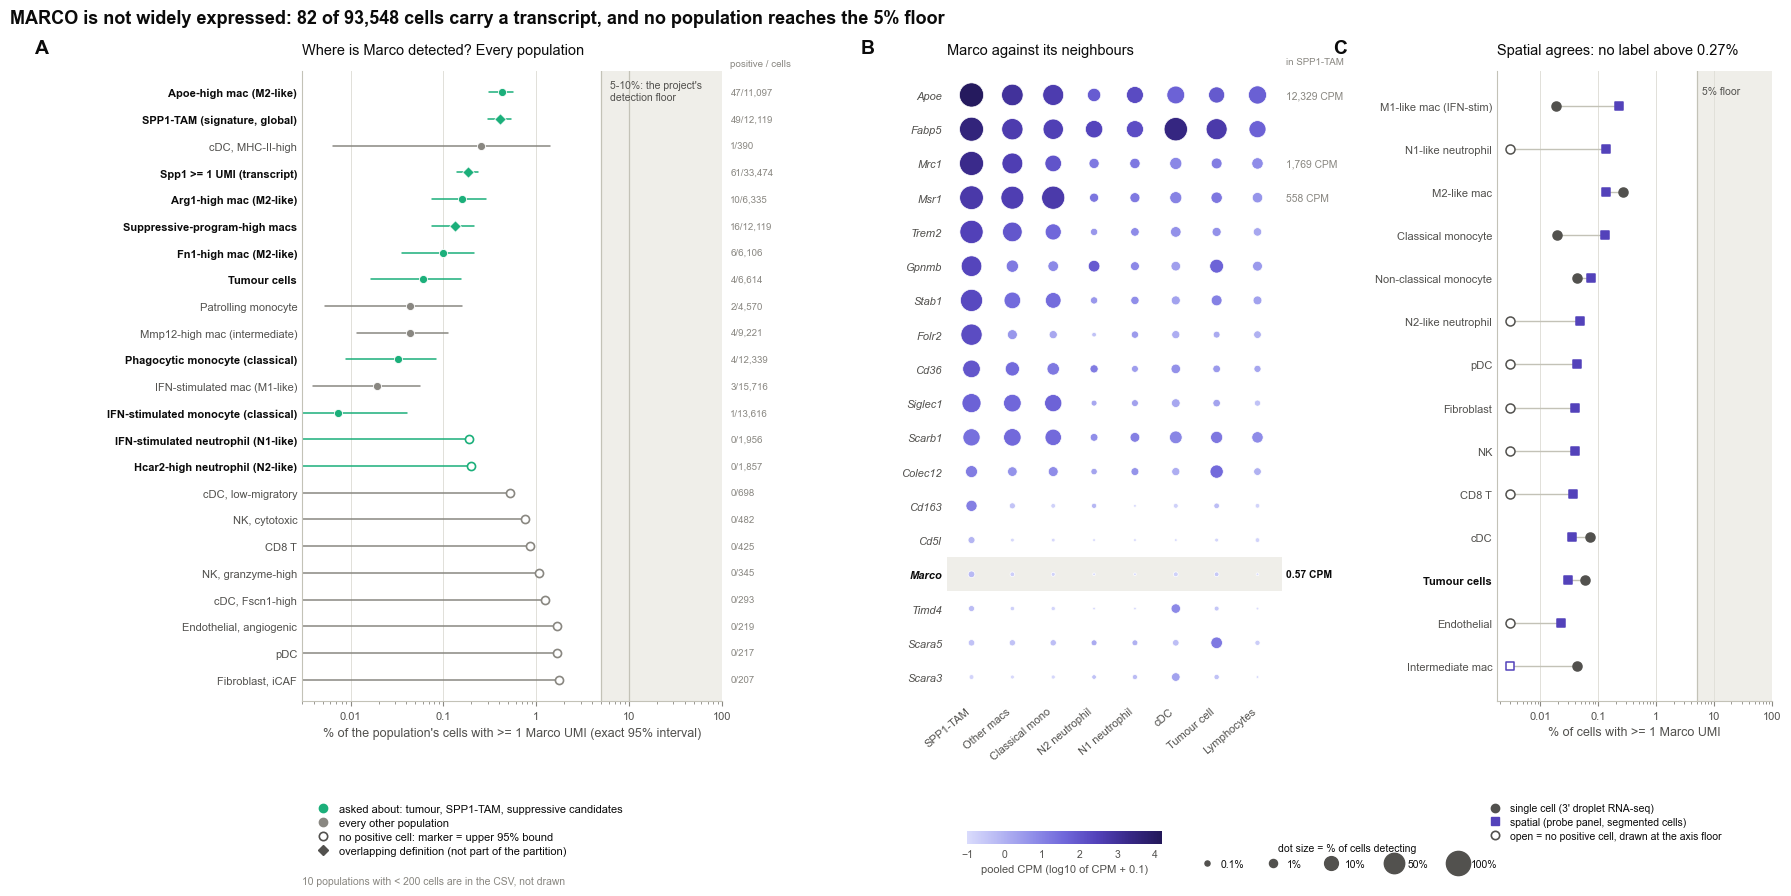

In [18]:
SHORT = {"SPP1_TAM": "SPP1-TAM", "other_mac": "Other macs", "Classical_Mono": "Classical mono", "N2_like_Neu": "N2 neutrophil",
         "N1_like_Neu": "N1 neutrophil", "cDC": "cDC", "Cancer_cell": "Tumour cell", "lymphocytes": "Lymphocytes"}
C_SP = "#5342ba"                      # spatial series (indigo, the magnitude hue); single cell = INK2


def corner(ax, letter, title, dx):
    """panel letter left of the tick labels (dx points) and the title above the axes."""
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(-dx, 10), textcoords="offset points", fontsize=14,
                fontweight="bold", ha="left", va="bottom", color=INK)
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(0, 10), textcoords="offset points", fontsize=10.5,
                ha="left", va="bottom", color=INK)


def hair(ax, axis="x"):
    ax.grid(True, axis=axis, color=GRID, lw=0.7); ax.set_axisbelow(True)


DISPLAYED.clear(); SOURCE.clear()
# ======================================== FIGURE 14A ===========================================================
FW, FH = 18.0, 9.2


def ax_in(left, bottom, width, height):                       # axes placed in inches, so label room is explicit
    return fig.add_axes([left / FW, bottom / FH, width / FW, height / FH])


fig = plt.figure(figsize=(FW, FH))
axA, axB, axC = ax_in(3.10, 2.05, 4.20, 6.30), ax_in(9.55, 2.05, 3.35, 6.30), ax_in(15.05, 2.05, 2.75, 6.30)

# ---- A: every population ---------------------------------------------------------------------------------------
ASKED = {"Cancer_cell", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Phagocytic_Mono", "IFN_stimulated_Mono", "Hcar2_high_Neu",
         "IFN_stimulated_Neu", "SPP1_TAM", "Spp1_pos", "SUPP_hi_mac"}
OVERLAP = {"SPP1_TAM", "Spp1_pos", "SUPP_hi_mac"}
A = pd.concat([BR[BR.kind == "lvl3 state"], BR.loc[["SPP1_TAM", "Spp1_pos", "SUPP_hi_mac"]]])
A = A[A.n >= 200].copy()
A = pd.concat([A[A.k > 0].sort_values("pct", ascending=False), A[A.k == 0].sort_values("n", ascending=False)])
n_hidden = int((BR[BR.kind == "lvl3 state"].n < 200).sum())
y = np.arange(len(A))[::-1]; XMIN = 0.003
axA.axvspan(DET_FLOOR_LOOSE, 100, color="#efeee9", lw=0, zorder=0)
axA.axvline(DET_FLOOR_LOOSE, color=AXIS, lw=0.9, zorder=1); axA.axvline(DET_FLOOR, color=AXIS, lw=0.9, zorder=1)
for yi, (nm, r) in zip(y, A.iterrows()):
    col = ACCENT if nm in ASKED else MUTED
    mk = "D" if nm in OVERLAP else "o"
    if r.k > 0:
        axA.plot([max(r.pct_lo, XMIN), r.pct_hi], [yi, yi], color=col, lw=1.1, zorder=2, solid_capstyle="round")
        axA.scatter(r.pct, yi, s=34, marker=mk, color=col, edgecolor="white", linewidth=0.6, zorder=3)
    else:
        axA.plot([XMIN, r.pct_hi], [yi, yi], color=col, lw=1.1, zorder=2, solid_capstyle="round")
        axA.scatter(r.pct_hi, yi, s=34, marker=mk, facecolor="white", edgecolor=col, linewidth=1.2, zorder=3)
    axA.text(1.02, yi, f"{int(r.k)}/{int(r.n):,}", transform=axA.get_yaxis_transform(), fontsize=7, color=MUTED, va="center", ha="left")
axA.set_xscale("log"); axA.set_xlim(XMIN, 100); axA.set_ylim(-0.8, len(A) - 0.2)
axA.set_xticks([0.01, 0.1, 1, 10, 100]); axA.set_xticklabels(["0.01", "0.1", "1", "10", "100"])
axA.set_yticks(y); axA.set_yticklabels([lab(i) for i in A.index])
for t_, nm in zip(axA.get_yticklabels(), A.index):
    if nm in ASKED: t_.set_fontweight("bold"); t_.set_color(INK)
axA.set_xlabel("% of the population's cells with >= 1 Marco UMI (exact 95% interval)")
axA.text(DET_FLOOR_LOOSE * 1.25, len(A) - 0.55, "5-10%: the project's\ndetection floor", fontsize=7.5, color=INK2, va="top", ha="left")
axA.text(1.02, 1.005, "positive / cells", transform=axA.transAxes, fontsize=7, color=MUTED, ha="left", va="bottom")
axA.tick_params(axis="y", length=0); hair(axA, "x")
corner(axA, "A", "Where is Marco detected? Every population", 192)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=ACCENT, ms=6, label="asked about: tumour, SPP1-TAM, suppressive candidates"),
                    Line2D([], [], marker="o", ls="", color=MUTED, ms=6, label="every other population"),
                    Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, mew=1.2, ms=6, label="no positive cell: marker = upper 95% bound"),
                    Line2D([], [], marker="D", ls="", color=INK2, ms=5, label="overlapping definition (not part of the partition)")],
           loc="upper left", bbox_to_anchor=(3.10 / FW, 1.12 / FH), ncol=1, frameon=False, fontsize=8, handletextpad=0.4, labelspacing=0.35)
fig.text(3.10 / FW, 0.22 / FH, f"{n_hidden} populations with < 200 cells are in the CSV, not drawn", fontsize=7.5, color=MUTED)
show_source("14A-A", A.reset_index()[["population", "kind", "n", "k", "pct", "pct_lo", "pct_hi", "cpm", "mice_positive", "mice_eligible"]])
show_stat("14A-A", statistic="cells with >= 1 Marco UMI, whole object", value=allc["pct"], k=allc["k"], n=allc["n"])
show_stat("14A-A", statistic="populations at >= 5% / >= 10%", value=int(BR.widely_loose.sum()), n_strict=int(BR.widely_strict.sum()), n_populations=len(BR))

# ---- B: Marco against its neighbours ----------------------------------------------------------------------------
gene_order = CMP.pivot(index="gene", columns="population", values="cpm")["SPP1_TAM"].sort_values(ascending=False).index.tolist()
cols = list(SHORT)
P = CMP.pivot(index="gene", columns="population", values="pct").reindex(gene_order)[cols]
Q = CMP.pivot(index="gene", columns="population", values="cpm").reindex(gene_order)[cols]
xx, yy = np.meshgrid(np.arange(len(cols)), np.arange(len(gene_order))[::-1])
ym = len(gene_order) - 1 - gene_order.index(MARCO)
axB.axhspan(ym - 0.5, ym + 0.5, color="#efeee9", lw=0, zorder=0)
sz = np.sqrt(P.values / 100) * 300 + 4
scb = axB.scatter(xx.ravel(), yy.ravel(), s=sz.ravel(), c=np.log10(Q.values.ravel() + 0.1), cmap=SEQ, vmin=-1, vmax=4.2,
                  edgecolor="white", linewidth=0.5, zorder=3)
axB.set_xticks(range(len(cols))); axB.set_xticklabels([SHORT[c] for c in cols], rotation=40, ha="right", fontsize=8)
axB.set_yticks(np.arange(len(gene_order))[::-1]); axB.set_yticklabels(gene_order, fontstyle="italic")
for t_ in axB.get_yticklabels():
    if t_.get_text() == MARCO: t_.set_fontweight("bold"); t_.set_color(INK)
axB.set_xlim(-0.6, len(cols) - 0.4); axB.set_ylim(-0.7, len(gene_order) - 0.3); axB.tick_params(length=0)
for sp_ in axB.spines.values(): sp_.set_visible(False)
for g_ in [MARCO, "Msr1", "Mrc1", "Apoe"]:                      # selective direct labels: the SPP1-TAM CPM of four reference genes
    v_ = Q.loc[g_, "SPP1_TAM"]
    axB.text(len(cols) - 0.3, len(gene_order) - 1 - gene_order.index(g_), f"{v_:,.{2 if v_ < 10 else 0}f} CPM", fontsize=7.5,
             color=INK if g_ == MARCO else MUTED, fontweight="bold" if g_ == MARCO else "normal", va="center", ha="left")
axB.text(len(cols) - 0.3, len(gene_order) - 0.15, "in SPP1-TAM", fontsize=7, color=MUTED, va="bottom", ha="left")
cax = fig.add_axes([9.75 / FW, 0.62 / FH, 1.95 / FW, 0.13 / FH]); cb = fig.colorbar(scb, cax=cax, orientation="horizontal")
cb.set_label("pooled CPM (log10 of CPM + 0.1)", fontsize=8); cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=7.5)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=INK2, ms=np.sqrt(np.sqrt(v / 100) * 300 + 4), label=f"{v:g}%") for v in (0.1, 1, 10, 50, 100)],
           title="dot size = % of cells detecting", loc="lower left", bbox_to_anchor=(11.95 / FW, 0.28 / FH), ncol=5, frameon=False, fontsize=7.5,
           title_fontsize=7.5, handletextpad=0.3, columnspacing=1.8)
corner(axB, "B", "Marco against its neighbours", 62)
show_source("14A-B", CMP.assign(panel_note="size = pct, colour = log10(cpm + 0.1)"))
show_stat("14A-B", statistic="SPP1-TAM CPM: Marco", value=float(Q.loc[MARCO, "SPP1_TAM"]), rank_from_bottom=rank_low, n_genes=len(gene_order),
          Msr1_over_Marco=float(Q.loc["Msr1", "SPP1_TAM"] / Q.loc[MARCO, "SPP1_TAM"]))

# ---- C: single cell against spatial, one dumbbell per label ---------------------------------------------------------------
if SP is not None:
    sc_lab = {c: pooled(CELL[CELL.ct2 == c]) for c in CELL.ct2.unique()}
    rows = [dict(label=l, sc_pct=sc_lab[l]["pct"], sc_k=sc_lab[l]["k"], sc_n=sc_lab[l]["n"], sp_pct=float(SP["tab"].loc[l, "pct"]),
                 sp_k=int(SP["tab"].loc[l, "k"]), sp_n=int(SP["tab"].loc[l, "n"]))
            for l in sc_lab if l in SP["tab"].index and sc_lab[l]["n"] >= 200 and SP["tab"].loc[l, "n"] >= 1000]
    V = pd.DataFrame(rows).sort_values("sp_pct", ascending=False).reset_index(drop=True)
    yv = np.arange(len(V))[::-1]; FLOORV = 0.003
    axC.axvspan(DET_FLOOR_LOOSE, 100, color="#efeee9", lw=0, zorder=0); axC.axvline(DET_FLOOR_LOOSE, color=AXIS, lw=0.9, zorder=1)
    for yi, r in zip(yv, V.itertuples()):
        xs, xp = max(r.sc_pct, FLOORV), max(r.sp_pct, FLOORV)
        axC.plot([xs, xp], [yi, yi], color=AXIS, lw=1.0, zorder=1)
        axC.scatter(xs, yi, marker="o", s=42, facecolor="white" if r.sc_pct == 0 else INK2, edgecolor=INK2, linewidth=1.1, zorder=3)
        axC.scatter(xp, yi, marker="s", s=38, facecolor="white" if r.sp_pct == 0 else C_SP, edgecolor=C_SP, linewidth=1.1, zorder=3)
    axC.set_xscale("log"); axC.set_xlim(FLOORV * 0.6, 100); axC.set_ylim(-0.8, len(V) - 0.2)
    axC.set_xticks([0.01, 0.1, 1, 10, 100]); axC.set_xticklabels(["0.01", "0.1", "1", "10", "100"])
    axC.set_yticks(yv); axC.set_yticklabels([lab(l) for l in V.label]); axC.tick_params(axis="y", length=0)
    for t_, l in zip(axC.get_yticklabels(), V.label):
        if l == "Cancer_cell": t_.set_fontweight("bold"); t_.set_color(INK)
    axC.set_xlabel("% of cells with >= 1 Marco UMI")
    axC.text(DET_FLOOR_LOOSE * 1.25, len(V) - 0.55, "5% floor", fontsize=7.5, color=INK2, va="top", ha="left"); hair(axC, "x")
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=INK2, ms=6, label="single cell (3' droplet RNA-seq)"),
                        Line2D([], [], marker="s", ls="", color=C_SP, ms=6, label="spatial (probe panel, segmented cells)"),
                        Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, mew=1.2, ms=6, label="open = no positive cell, drawn at the axis floor")],
               loc="upper left", bbox_to_anchor=(15.05 / FW - 0.012, 1.12 / FH), ncol=1, frameon=False, fontsize=7.5, handletextpad=0.4, labelspacing=0.35)
    show_source("14A-C", V)
    show_stat("14A-C", statistic="spatial: cells with >= 1 Marco UMI", value=SP["pct"], k=SP["k"], n=SP["n"], best_label=SP["best_label"], best_pct=SP["best_pct"],
              B_cell_floor_pct=SP["b_pct"], any_label_measurable=SP["any_measurable"])
    corner(axC, "C", f"Spatial agrees: no label above {max(V.sp_pct.max(), V.sc_pct.max()):.2f}%", 118)
fig.suptitle(f"MARCO is not widely expressed: {allc['k']} of {allc['n']:,} cells carry a transcript, and no population reaches the 5% floor",
             x=0.01, ha="left", y=0.975, fontsize=13, fontweight="bold", color=INK)
save_figure(fig, "fig14A_marco_breadth"); plt.show()
pd.DataFrame(DISPLAYED).to_csv(FIG/"fig14A_marco_breadth_displayed_stats.csv", index=False)
pd.concat(SOURCE, ignore_index=True).to_csv(FIG/"fig14A_marco_breadth_source_data.csv", index=False)

saved /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_marco/figures/fig14B_marco_where.pdf / .svg / .png


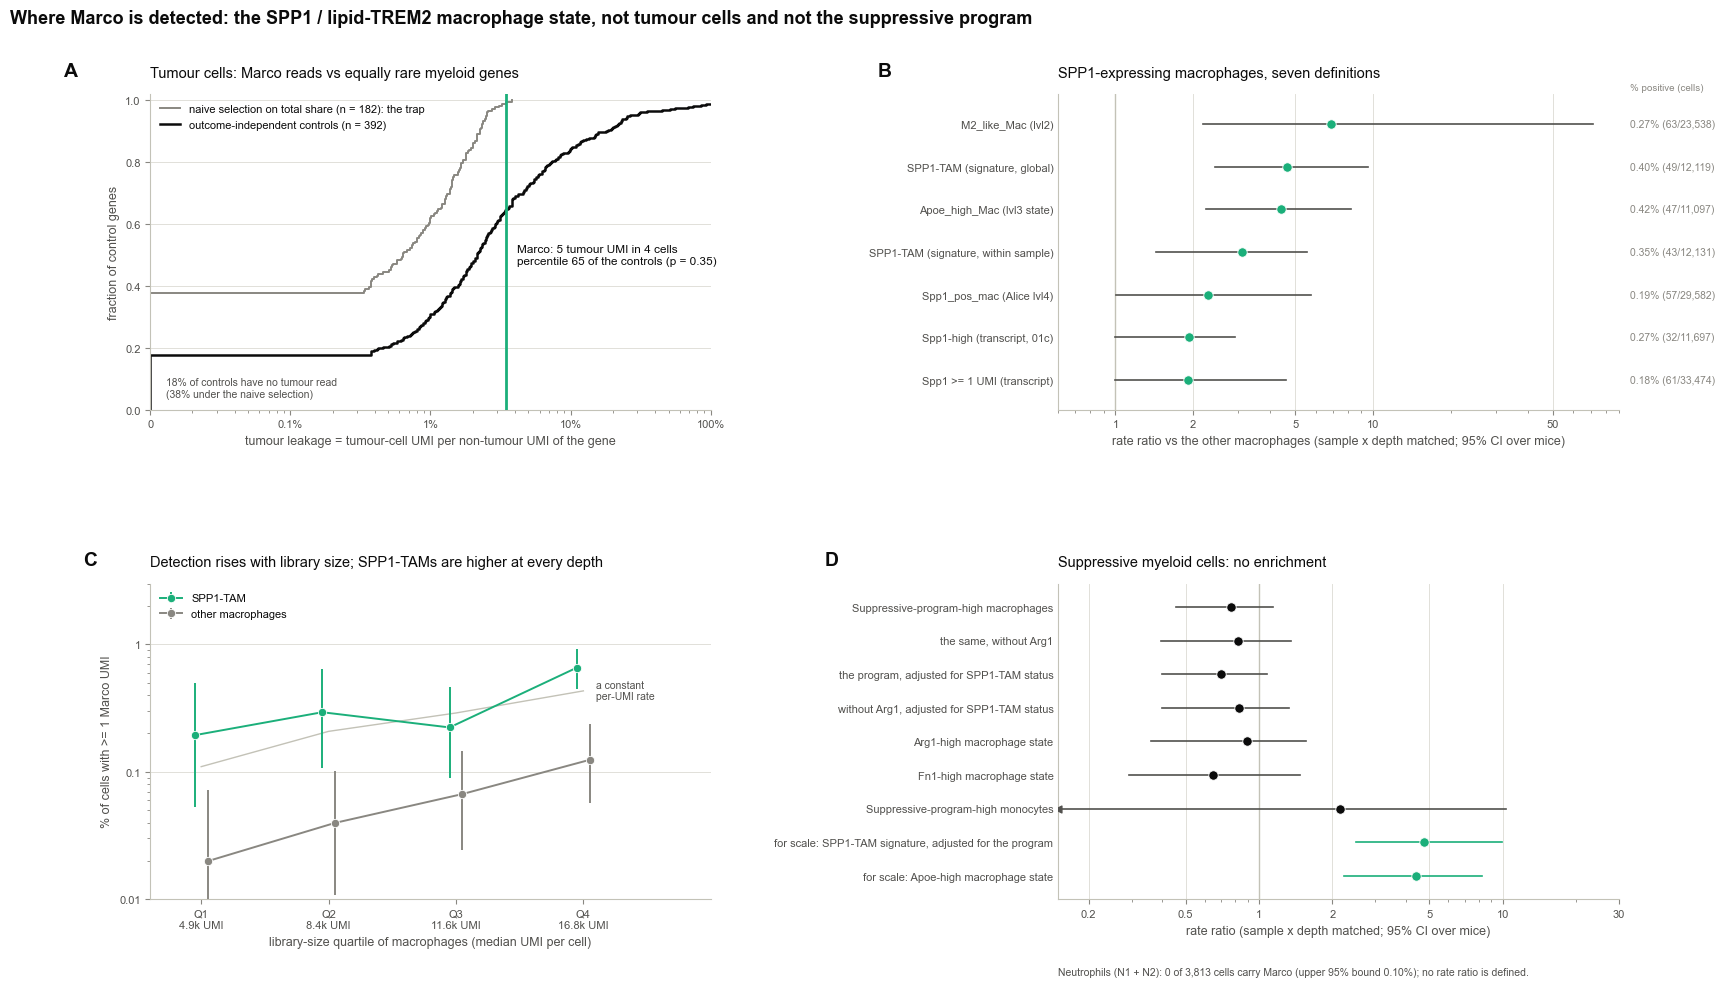

In [19]:
# ======================================== FIGURE 14B ===========================================================
DISPLAYED.clear(); SOURCE.clear()
fig = plt.figure(figsize=(16.5, 10.0))
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.0], height_ratios=[1.0, 1.0], wspace=0.62, hspace=0.55, left=0.095, right=0.985, top=0.9, bottom=0.095)
axA, axB, axC, axD = [fig.add_subplot(gs[i // 2, i % 2]) for i in range(4)]


def ecdf(v):
    v = np.sort(np.clip(np.asarray(v, float), 1e-4, None)); return v, np.arange(1, len(v) + 1) / len(v)


# ---- A: tumour leakage against matched controls ---------------------------------------------------------------------
prim, naive = control_set(2.0, 0.95, False, False), control_set(2.0, 0.95, False, True)
x1, y1 = ecdf(prim.leak); x2, y2 = ecdf(naive.leak)
axA.step(x2, y2, where="post", color=MUTED, lw=1.4, label=f"naive selection on total share (n = {len(naive)}): the trap")
axA.step(x1, y1, where="post", color=INK, lw=1.8, label=f"outcome-independent controls (n = {len(prim)})")
axA.axvline(mk_.leak, color=ACCENT, lw=2.0, zorder=4)
axA.annotate(f"Marco: {int(mk_.tum)} tumour UMI in {int(mk_.tum_cells)} cells\npercentile {TUM_RES['pctile_primary']:.0f} of the controls (p = {TUM_RES['p_primary']:.2f})",
             (mk_.leak, 0.50), xytext=(8, 0), textcoords="offset points", fontsize=8.5, color=INK, va="center", ha="left")
axA.annotate(f"{100*np.mean(prim.leak == 0):.0f}% of controls have no tumour read\n({100*np.mean(naive.leak == 0):.0f}% under the naive selection)",
             (1.3e-4, 0.07), fontsize=7.5, color=INK2, va="center", ha="left")
axA.set_xscale("log"); axA.set_xlim(1e-4, 1.0); axA.set_ylim(0, 1.02)
axA.set_xticks([1e-4, 1e-3, 1e-2, 1e-1, 1]); axA.set_xticklabels(["0", "0.1%", "1%", "10%", "100%"])
axA.set_xlabel("tumour leakage = tumour-cell UMI per non-tumour UMI of the gene"); axA.set_ylabel("fraction of control genes")
axA.legend(loc="upper left", frameon=False, fontsize=8, handlelength=1.8); hair(axA, "y")
corner(axA, "A", "Tumour cells: Marco reads vs equally rare myeloid genes", 62)
show_source("14B-A", pd.concat([pd.DataFrame({"set": "outcome-independent", "leak": np.sort(prim.leak.values)}),
                                pd.DataFrame({"set": "naive", "leak": np.sort(naive.leak.values)})]))
show_stat("14B-A", statistic="Marco tumour leakage percentile among matched controls (primary)", value=TUM_RES["pctile_primary"], p_empirical=TUM_RES["p_primary"],
          range_over_12_variants=f"{TUM_RES['pctile_lo']:.0f}-{TUM_RES['pctile_hi']:.0f}", naive_percentile=f"{TUM_RES['naive_lo']:.0f}-{TUM_RES['naive_hi']:.0f}")

# ---- B: rate ratio across the seven SPP1 definitions ------------------------------------------------------------------
Bd = S3.sort_values("rr")
yb = np.arange(len(Bd))
axB.axvline(1, color=AXIS, lw=1.0, zorder=1)
for yi, (d, r) in zip(yb, Bd.iterrows()):
    axB.plot([max(r.rr_lo, 0.6), min(r.rr_hi, 90)], [yi, yi], color=INK2, lw=1.2, zorder=2)
    axB.scatter(r.rr, yi, s=46, color=ACCENT, edgecolor="white", linewidth=0.6, zorder=3)
    axB.text(1.02, yi, f"{r.pct:.2f}% ({int(r.k)}/{int(r.n):,})", transform=axB.get_yaxis_transform(), fontsize=7.5, color=MUTED, va="center")
axB.set_xscale("log"); axB.set_xlim(0.6, 90); axB.set_xticks([1, 2, 5, 10, 50]); axB.set_xticklabels(["1", "2", "5", "10", "50"])
axB.set_yticks(yb); axB.set_yticklabels([lab(d) for d in Bd.index]); axB.tick_params(axis="y", length=0); axB.set_ylim(-0.7, len(Bd) - 0.3)
axB.set_xlabel("rate ratio vs the other macrophages (sample x depth matched; 95% CI over mice)")
axB.text(1.02, 1.005, "% positive (cells)", transform=axB.transAxes, fontsize=7, color=MUTED, ha="left", va="bottom"); hair(axB, "x")
corner(axB, "B", "SPP1-expressing macrophages, seven definitions", 130)
show_source("14B-B", S3.reset_index()[["definition", "n", "k", "pct", "cpm", "cpm_rest", "rr", "rr_lo", "rr_hi", "p_perm", "dcpm", "p_mouse", "mice_A_gt_B", "mice_tested"]])
show_stat("14B-B", statistic="RR range over seven SPP1 definitions", value=f"{S3.rr.min():.2f}-{S3.rr.max():.2f}", all_above_1=bool((S3.rr > 1).all()),
          highest_pct=float(S3.pct.max()))

# ---- C: depth-matched detection, SPP1-TAM vs other macrophages ------------------------------------------------------------
dqa = DQ[DQ.group == "all macrophages"].set_index("depth_q")
xq = np.arange(1, 5)
for grp, col, off in [("SPP1-TAM", ACCENT, -0.05), ("other macrophages", MUTED, 0.05)]:
    d = DQ[DQ.group == grp].set_index("depth_q").loc[xq]
    yv = np.clip(d.pct.values, 1e-3, None)
    axC.errorbar(xq + off, yv, yerr=[yv - np.clip(d.pct_lo.values, 1e-3, None), d.pct_hi.values - yv], color=col, lw=1.4, marker="o", ms=6, mec="white",
                 mew=0.6, capsize=0, zorder=3, label=grp)
axC.plot(xq, dqa.loc[xq, "expected_pct_constant_cpm"], color=AXIS, lw=1.0, zorder=1)
axC.text(4.1, float(dqa.loc[4, "expected_pct_constant_cpm"]), "a constant\nper-UMI rate", fontsize=7.5, color=INK2, va="center", ha="left")
axC.set_yscale("log"); axC.set_ylim(0.01, 3); axC.set_xlim(0.6, 5.0)
axC.set_yticks([0.01, 0.1, 1]); axC.set_yticklabels(["0.01", "0.1", "1"])
axC.set_xticks(xq); axC.set_xticklabels([f"Q{q}\n{dqa.loc[q, 'median_depth']/1000:.1f}k UMI" for q in xq])
axC.set_xlabel("library-size quartile of macrophages (median UMI per cell)"); axC.set_ylabel("% of cells with >= 1 Marco UMI")
axC.legend(loc="upper left", frameon=False, fontsize=8); hair(axC, "y")
corner(axC, "C", "Detection rises with library size; SPP1-TAMs are higher at every depth", 48)
show_source("14B-C", DQ)
show_stat("14B-C", statistic="detection ~ depth^beta within sample", value=b, ci_lo=b - 1.96 * se, ci_hi=b + 1.96 * se)

# ---- D: the suppressive definitions -------------------------------------------------------------------------------------
def pick(df, **kw):
    for k, v in kw.items(): df = df[df[k] == v]
    return df.iloc[0]


ROWS = [("Suppressive-program-high macrophages", pick(PROG, lineage="Macrophage", score="SUPP"), INK),
        ("the same, without Arg1", pick(PROG, lineage="Macrophage", score="SUPP_noArg1"), INK),
        ("the program, adjusted for SPP1-TAM status", pick(ADJ, axis="suppressive program", adjusted_for="SPP1-TAM status"), INK),
        ("without Arg1, adjusted for SPP1-TAM status", pick(ADJ, axis="suppressive program, no Arg1", adjusted_for="SPP1-TAM status"), INK),
        ("Arg1-high macrophage state", pick(ST, state="Arg1_high_Mac"), INK),
        ("Fn1-high macrophage state", pick(ST, state="Fn1_high_Mac"), INK),
        ("Suppressive-program-high monocytes", pick(PROG, lineage="Monocyte", score="SUPP"), INK),
        ("for scale: SPP1-TAM signature, adjusted for the program", pick(ADJ, axis="SPP1-TAM (signature)", adjusted_for="suppressive program"), ACCENT),
        ("for scale: Apoe-high macrophage state", S3.loc["Apoe_high_state"], ACCENT)]
yd = np.arange(len(ROWS))[::-1]; lo_lim, hi_lim = 0.15, 30
axD.axvline(1, color=AXIS, lw=1.0, zorder=1)
src_d = []
for yi, (nm, r, col) in zip(yd, ROWS):
    lo_, hi_ = max(r["rr_lo"], lo_lim), min(r["rr_hi"], hi_lim)
    axD.plot([lo_, hi_], [yi, yi], color=INK2 if col == INK else col, lw=1.2, zorder=2)
    if r["rr_lo"] < lo_lim: axD.scatter(lo_lim, yi, marker="<", s=24, color=INK2, zorder=3)
    axD.scatter(r["rr"], yi, s=46, color=col, edgecolor="white", linewidth=0.6, zorder=3)
    src_d.append(dict(row=nm.strip(), rr=r["rr"], rr_lo=r["rr_lo"], rr_hi=r["rr_hi"]))
axD.set_xscale("log"); axD.set_xlim(lo_lim, hi_lim); axD.set_xticks([0.2, 0.5, 1, 2, 5, 10, 30]); axD.set_xticklabels(["0.2", "0.5", "1", "2", "5", "10", "30"])
axD.set_yticks(yd); axD.set_yticklabels([r[0] for r in ROWS]); axD.tick_params(axis="y", length=0); axD.set_ylim(-0.7, len(ROWS) - 0.3)
axD.set_xlabel("rate ratio (sample x depth matched; 95% CI over mice)"); hair(axD, "x")
nn = BR.loc[["neu_all"]].iloc[0]
axD.text(0.0, -0.24, f"Neutrophils (N1 + N2): {int(nn.k)} of {int(nn.n):,} cells carry Marco (upper 95% bound {nn.pct_hi:.2f}%); no rate ratio is defined.",
         transform=axD.transAxes, fontsize=7.5, color=INK2)
corner(axD, "D", "Suppressive myeloid cells: no enrichment", 168)
show_source("14B-D", pd.DataFrame(src_d))
show_stat("14B-D", statistic="suppressive-program-high macs, adjusted RR", value=float(ROWS[2][1]["rr"]), ci_lo=float(ROWS[2][1]["rr_lo"]), ci_hi=float(ROWS[2][1]["rr_hi"]),
          SPP1_TAM_adjusted_RR=float(ROWS[7][1]["rr"]))
fig.suptitle("Where Marco is detected: the SPP1 / lipid-TREM2 macrophage state, not tumour cells and not the suppressive program",
             x=0.01, ha="left", y=0.985, fontsize=13, fontweight="bold", color=INK)
save_figure(fig, "fig14B_marco_where"); plt.show()
pd.DataFrame(DISPLAYED).to_csv(FIG/"fig14B_marco_where_displayed_stats.csv", index=False)
pd.concat(SOURCE, ignore_index=True).to_csv(FIG/"fig14B_marco_where_source_data.csv", index=False)

## 12. Summary

In [20]:
top = BR[BR.kind == "lvl3 state"].sort_values("pct", ascending=False).iloc[0]; topn = BR[BR.kind == "lvl3 state"].sort_values("pct", ascending=False).index[0]
tam, apo = S3.loc["SPP1_TAM"], S3.loc["Apoe_high_state"]
bt_tam = mouse_boot_pooled(CELL[CELL.SPP1_TAM]); c_ = CLS
sup_m = pick(PROG, lineage="Macrophage", score="SUPP"); sup_adj = pick(ADJ, axis="suppressive program", adjusted_for="SPP1-TAM status")
tam_adj = pick(ADJ, axis="SPP1-TAM (signature)", adjusted_for="suppressive program")
co_sup = CO[CO.set == "suppressive program"]; co_lip = CO[CO.set == "lipid / TREM2 program"]
n_pos_s, n_pos_m = int((CELL.groupby("sample").pos.sum() > 0).sum()), int((CELL.groupby("mouse").pos.sum() > 0).sum())

print("=" * 110); print("SUMMARY — report these back"); print("=" * 110)
print(f"[data] {len(CELL):,} cells, {CELL['sample'].nunique()} tumours, {CELL.mouse.nunique()} mice; Marco = chr1 feature, counts layer; mouse = unit.")

print("\n1. IS MARCO WIDELY EXPRESSED?  NO — NOT IN ANY CELL TYPE, MOUSE OR CONDITION")
print(f"  * {allc['k']} of {allc['n']:,} cells ({allc['pct']:.3f}%) carry >= 1 Marco UMI ({allc['umi']} UMI in total; Msr1 has {int(CELL['Msr1'].sum()):,}). "
      f"{n_pos_s}/{CELL['sample'].nunique()} tumours and {n_pos_m}/{CELL.mouse.nunique()} mice have a positive cell; one mouse carries {100*um.iloc[0]/um.sum():.0f}% of the UMI.")
print(f"  * {int(BR.widely_loose.sum())} of {len(BR)} populations reach the 5% floor. Highest: {lab(topn)} {top.pct:.2f}% ({int(top.k)}/{int(top.n):,}) = "
      f"{DET_FLOOR_LOOSE/top.pct:.0f}x below it; pooled CPM <= {BR.loc[BR.kind == 'lvl3 state', 'cpm'].max():.2f} "
      f"(Msr1 is x{cp_t.loc['Msr1', 'SPP1_TAM']/cp_t.loc[MARCO, 'SPP1_TAM']:,.0f} higher in SPP1-TAMs; Marco ranks {rank_low} from the bottom of an {len(CMP_GENES)}-gene panel).")
print(f"  * Detection rises with library size (depth^{b:.1f}), so the positive fraction is a lower bound on a rare transcript, not proof of absence.")
if SP is not None:
    print(f"  * Spatial (a different chemistry) agrees: {SP['pct']:.3f}% of {SP['n']:,} cells; best label {SP['best_label']} {SP['best_pct']:.2f}%; "
          f"measurable (>= 5% and >= 1.5x B cells) in any label: {SP['any_measurable']}.")

print("\n2. THE THREE POPULATIONS YOU ASKED ABOUT")
print(f"  TUMOUR CELLS: {TUM_RES['k']}/{TUM_RES['n']:,} ({TUM_RES['pct']:.3f}%, at most {TUM_RES['pct_hi']:.2f}%). Indistinguishable from the leakage any equally rare myeloid gene shows in tumour cells "
      f"(percentile {TUM_RES['pctile_primary']:.0f}, p = {TUM_RES['p_primary']:.2f}; {TUM_RES['pctile_lo']:.0f}-{TUM_RES['pctile_hi']:.0f} over 12 control variants). "
      f"{TUM_RES['dirty_pos']} of {TUM_RES['pos_total']} positive cells also carry macrophage-marker reads (tumour base rate {TUM_RES['dirty_frac']:.0f}%). Spatial: below the B-cell floor.")
print(f"  SPP1-EXPRESSING MACROPHAGES: {tam['pct']:.2f}% of SPP1-TAMs (mouse-bootstrap CI {bt_tam['pct_mouse_lo']:.2f}-{bt_tam['pct_mouse_hi']:.2f}%), {apo['pct']:.2f}% of Apoe-high macs. "
      f"More than other macrophages at matched depth and sample (rate ratio {S3.rr.min():.1f}-{S3.rr.max():.1f} over seven definitions; SPP1-TAM {tam['rr']:.1f} [{tam['rr_lo']:.1f}, {tam['rr_hi']:.1f}]; "
      f"higher in {int(tam['mice_A_gt_B'])}/{int(tam['mice_tested'])} mice, p = {tam['p_mouse']:.3f}) — enriched, but still rare. It follows the Apoe-high / lipid-TREM2 state "
      f"({int(((co_lip.q_BH < .05) & (co_lip.rr > 1)).sum())} of {len(co_lip)} lipid/TREM2 genes up in Marco+ cells), not the Spp1 transcript (RR {S3.loc['Spp1_high', 'rr']:.1f} for Spp1-high, {S3.loc['Spp1_pos', 'rr']:.1f} for Spp1 >= 1 UMI).")
print(f"  SUPPRESSIVE MYELOID CELLS: M2-like TAM states {c_.iloc[0].pct:.2f}% (Arg1-high {c_.iloc[1].pct:.2f}%), classical monocytes {c_.iloc[3].pct:.3f}% ({int(c_.iloc[3].k)}/{int(c_.iloc[3].n):,}), "
      f"N2-like neutrophils {int(c_.iloc[4].k)}/{int(c_.iloc[4].n):,}, N1-like {int(c_.iloc[5].k)}/{int(c_.iloc[5].n):,}. Cells high on a pre-specified suppressive program are not enriched "
      f"(rate ratio {sup_m['rr']:.2f} [{sup_m['rr_lo']:.2f}, {sup_m['rr_hi']:.2f}]; {sup_adj['rr']:.2f} adjusted for SPP1-TAM status) while SPP1-TAM stays {tam_adj['rr']:.1f}x after adjusting for the program; "
      f"{int(((co_sup.q_BH < .05) & (co_sup.rr > 1)).sum())} of {len(co_sup)} suppressive effector genes are up in Marco+ cells.")

print("\n3. OTHER CHECKS")
print(f"  * Conditions: no arm x site above {AR.pct.max():.2f}% of macrophages; PSCA - TAG72 {EX.iloc[0]['diff']:+.2f} CPM (p = {EX.iloc[0]['p_exact']:.2f}), RT - no RT {EX.iloc[1]['diff']:+.2f} (p = {EX.iloc[1]['p_exact']:.2f}); "
      f"a 6 v 6 contrast could only see ~{mde:.1f} CPM — underpowered, no claim.")
print(f"  * Earlier work: 01c's lipid/TREM2 check had Marco as the one non-significant gene (log2FC +1.92, padj 1.0) — same direction as here, on ~0.3% of cells. "
      f"Marco is <= {PW.marco_share_pct.max():.3f}% of any pathway set's UMI in SPP1-TAMs, so no pathway result in 01c / 10 can be attributed to it.")

print("\n4. WHAT THE RESULTS PERMIT US TO CLAIM")
print("  * At the RNA level Marco is a rare transcript in this model (< 0.5% of cells in any population, single cell and spatial). It is not an expressed feature of tumour cells, "
      "SPP1-TAMs as a population, or suppressive myeloid cells.")
print("  * Where it is detected it sits in the Apoe-high / lipid-TREM2 macrophage state, not with Spp1 transcript and not with the suppressive program.")
print("  * NOT supported: 'MARCO+ SPP1-TAMs' as a population, MARCO in tumour cells, MARCO as a marker of suppressive myeloid cells, or Marco as a per-cell spatial readout.")
print("  * Not measured: MARCO protein. A transcript this rare can still go with detectable protein; flow or IHC is the decisive test.")
print(f"\n[files] {OUT}: 14_*.csv | {FIG}: fig14A_marco_breadth.(pdf|svg|png), fig14B_marco_where.(pdf|svg|png) + _displayed_stats.csv, _source_data.csv")
print("=" * 110)

SUMMARY — report these back
[data] 93,548 cells, 29 tumours, 15 mice; Marco = chr1 feature, counts layer; mouse = unit.

1. IS MARCO WIDELY EXPRESSED?  NO — NOT IN ANY CELL TYPE, MOUSE OR CONDITION
  * 82 of 93,548 cells (0.088%) carry >= 1 Marco UMI (149 UMI in total; Msr1 has 334,646). 19/29 tumours and 13/15 mice have a positive cell; one mouse carries 36% of the UMI.
  * 0 of 42 populations reach the 5% floor. Highest: Apoe-high mac (M2-like) 0.42% (47/11,097) = 12x below it; pooled CPM <= 0.59 (Msr1 is x976 higher in SPP1-TAMs; Marco ranks 4 from the bottom of an 18-gene panel).
  * Detection rises with library size (depth^1.7), so the positive fraction is a lower bound on a rare transcript, not proof of absence.
  * Spatial (a different chemistry) agrees: 0.060% of 2,088,557 cells; best label M1_like_Mac 0.23%; measurable (>= 5% and >= 1.5x B cells) in any label: False.

2. THE THREE POPULATIONS YOU ASKED ABOUT
  TUMOUR CELLS: 4/6,614 (0.060%, at most 0.15%). Indistinguishable fr